
# 08 — Localization Analysis and Attribution Visualization

## 1. Overview

This notebook extends the stability–localization disagreement analysis by examining how radiologist-annotated opacity regions influence localization measurements.

The previous analyses measured localization alignment as the proportion of attribution magnitude falling inside annotated opacity bounding boxes. However, the size of these regions varies between images, which may influence how alignment scores are interpreted.

This notebook investigates:

1. The proportion of image area covered by opacity annotations.
2. Localization alignment relative to the annotated area.
3. Differences in localization measurements across XAI methods and corruption conditions.
4. Spatial attribution patterns in selected disagreement cases.

The original localization metric is retained for comparison. Additional measurements are treated as complementary descriptive analyses rather than replacements for the existing evaluation.



## 2. Data Access

This section connects Google Colab to Google Drive and defines the locations of the saved evaluation results and annotation files.

The analysis uses previously generated evaluation results from Notebook 06. The original annotation records are required to reconstruct opacity bounding-box masks and calculate the fraction of image area covered by those boxes.

File paths are specified explicitly so that the notebook can access data stored in separate Google Drive directories.


In [ ]:
from google.colab import drive
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

drive.mount("/content/drive")

# Update these paths to match your existing Google Drive folders.
RESULTS_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation"
)
ANNOTATIONS_PATH = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

AUDIT_PATH = RESULTS_DIR / "stability_localization_audit.csv"

assert AUDIT_PATH.is_file(), f"Missing audit CSV: {AUDIT_PATH}"
assert ANNOTATIONS_PATH.is_file(), f"Missing annotation file: {ANNOTATIONS_PATH}"

audit = pd.read_csv(AUDIT_PATH)

print("Audit shape:", audit.shape)
print("Unique images:", audit["sop_uid"].nunique())
print("Annotation file:", ANNOTATIONS_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Audit shape: (2700, 20)
Unique images: 150
Annotation file: /content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pneumonia-challenge-annotations-adjudicated-kaggle_2018.json


## 3. Bounding-Box Area Coverage

This analysis examines how the size of radiologist-annotated lung-opacity regions influences the interpretation of localization alignment.

Because annotated opacity regions vary considerably in size across images, the same localization alignment value may have different implications depending on the proportion of image area covered by the annotations.

The following sections extract the relevant opacity annotations, construct bounding-box masks, and calculate the fraction of image area occupied by the annotated regions. These measurements provide the basis for area-adjusted attribution analysis.

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
import json

with open(ANNOTATIONS_PATH, "r") as f:
    annotations = json.load(f)

print("Top-level type:", type(annotations).__name__)

if isinstance(annotations, list):
    print("Number of records:", len(annotations))
    if annotations:
        print("First record:")
        print(json.dumps(annotations[0], indent=2)[:2000])

elif isinstance(annotations, dict):
    print("Top-level keys:", list(annotations.keys())[:20])
    print("First entry preview:")
    first_key = next(iter(annotations), None)
    if first_key is not None:
        print(json.dumps(annotations[first_key], indent=2)[:2000])

Top-level type: dict
Top-level keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'isPrivate', 'labelGroups', 'datasets']
First entry preview:
"x9N20BZa"


In [ ]:
# Inspect the structure of the datasets field
datasets = annotations.get("datasets")

print("Datasets type:", type(datasets).__name__)

if isinstance(datasets, list):
    print("Number of datasets:", len(datasets))

    if datasets:
        first_dataset = datasets[0]
        print("First dataset type:", type(first_dataset).__name__)

        if isinstance(first_dataset, dict):
            print("First dataset keys:", list(first_dataset.keys()))

elif isinstance(datasets, dict):
    print("Dataset keys:", list(datasets.keys())[:20])

# Inspect the label groups
label_groups = annotations.get("labelGroups")

print("\nLabel groups type:", type(label_groups).__name__)

if isinstance(label_groups, list):
    print("Number of label groups:", len(label_groups))

    if label_groups:
        print(
            "First label group keys:",
            (
                list(label_groups[0].keys())
                if isinstance(label_groups[0], dict)
                else type(label_groups[0]).__name__
            ),
        )

Datasets type: list
Number of datasets: 1
First dataset type: dict
First dataset keys: ['id', 'type', 'createdAt', 'updatedAt', 'name', 'description', 'studies', 'annotations']

Label groups type: list
Number of label groups: 7
First label group keys: ['id', 'createdAt', 'updatedAt', 'name', 'description', 'labels']


In [ ]:
# Access the annotation records in the first dataset
annotation_records = annotations["datasets"][0]["annotations"]

print("Annotation records type:", type(annotation_records).__name__)

print("Number of annotation records:", len(annotation_records))

# Inspect the first annotation record
if isinstance(annotation_records, list) and annotation_records:
    print("\nFirst annotation record:")
    print(json.dumps(annotation_records[0], indent=2)[:2000])

elif isinstance(annotation_records, dict):
    print("\nFirst annotation keys:")
    print(list(annotation_records.keys())[:20])

Annotation records type: list
Number of annotation records: 83809

First annotation record:
{
  "id": "A_e5227e",
  "createdAt": "2018-03-24T23:00:19.392Z",
  "createdById": "U_rk3",
  "updatedAt": "2018-03-24T23:00:19.398Z",
  "updatedById": "U_rk3",
  "machineLearningModelId": null,
  "StudyInstanceUID": "1.2.276.0.7230010.3.1.2.8323329.6749.1517874327.608586",
  "SeriesInstanceUID": "1.2.276.0.7230010.3.1.3.8323329.6749.1517874327.608585",
  "SOPInstanceUID": "1.2.276.0.7230010.3.1.4.8323329.6749.1517874327.608587",
  "labelId": "L_1el",
  "annotationNumber": null,
  "height": null,
  "width": null,
  "data": null,
  "note": null,
  "radlexTagIds": [],
  "reviewsPositiveCount": 0,
  "reviewsNegativeCount": 0
}



## 4. Extracting Lung-Opacity Bounding Boxes

The annotation dataset contains multiple annotation types, including records without bounding-box coordinates.

To maintain consistency with the localization analysis in Notebook 06, this section selects annotations with the label ID `L_v8n`, corresponding to the final adjudicated lung-opacity bounding boxes used in the previous experiments.

Records are grouped by `SOPInstanceUID`, allowing images with multiple opacity boxes to retain all their annotations.

The extracted annotations will be used to construct binary masks and calculate the fraction of image area covered by opacity regions.


In [ ]:
from collections import defaultdict

# Use the same opacity label as Notebook 06
OPACITY_LABEL_ID = "L_v8n"

opacity_records = [
    record
    for record in annotation_records
    if record.get("labelId") == OPACITY_LABEL_ID
    and isinstance(record.get("data"), dict)
]

# Group bounding boxes by image identifier
opacity_lookup = defaultdict(list)

for record in opacity_records:
    uid = str(record["SOPInstanceUID"])
    opacity_lookup[uid].append(record)

print("Total opacity bounding boxes:", len(opacity_records))
print("Images with opacity boxes:", len(opacity_lookup))

# Check overlap with the 150 images in our audit
audit_uids = set(audit["sop_uid"].astype(str))
matched_uids = audit_uids.intersection(opacity_lookup.keys())

print("Audit images:", len(audit_uids))
print("Audit images with opacity boxes:", len(matched_uids))

missing_uids = audit_uids - set(opacity_lookup.keys())

print("Audit images missing opacity boxes:", len(missing_uids))

Total opacity bounding boxes: 11390
Images with opacity boxes: 7106
Audit images: 150
Audit images with opacity boxes: 150
Audit images missing opacity boxes: 0



## 5. Bounding-Box Area Fractions

This section converts the extracted lung-opacity bounding boxes into binary masks at the model input resolution of 320 × 384 pixels.

Bounding-box coordinates are scaled from their original annotation dimensions to the model input dimensions. The masks represent the union of all annotated opacity regions for each image.

The area fraction is calculated as:

$
\text{Box Area Fraction} =
\frac{\text{Number of Pixels Inside Opacity Boxes}}
{\text{Total Number of Image Pixels}}
$

This measurement describes the proportion of each image occupied by annotated opacity regions, independently of the XAI method.


In [ ]:
IMAGE_HEIGHT = 320
IMAGE_WIDTH = 384


def calculate_box_area_fraction(boxes, height=320, width=384):

    mask = np.zeros((height, width), dtype=bool)

    for record in boxes:
        box = record["data"]

        sx = width / record["width"]
        sy = height / record["height"]

        x1 = int(np.floor(box["x"] * sx))
        y1 = int(np.floor(box["y"] * sy))
        x2 = int(np.ceil((box["x"] + box["width"]) * sx))
        y2 = int(np.ceil((box["y"] + box["height"]) * sy))

        x1, x2 = np.clip([x1, x2], 0, width)
        y1, y2 = np.clip([y1, y2], 0, height)

        mask[y1:y2, x1:x2] = True

    return mask.mean()


area_records = []

for uid in sorted(audit_uids):

    if uid not in opacity_lookup:
        continue

    boxes = opacity_lookup[uid]

    area_records.append(
        {
            "sop_uid": uid,
            "n_boxes": len(boxes),
            "box_area_fraction": calculate_box_area_fraction(boxes),
        }
    )

area_df = pd.DataFrame(area_records)

display(area_df.head())

print("\nArea fraction summary:")
display(area_df["box_area_fraction"].describe())

,sop_uid,n_boxes,box_area_fraction
0,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,2,0.041162
1,1.2.276.0.7230010.3.1.4.8323329.10293.15178743...,2,0.108765
2,1.2.276.0.7230010.3.1.4.8323329.10662.15178743...,2,0.195052
3,1.2.276.0.7230010.3.1.4.8323329.10679.15178743...,2,0.202010
4,1.2.276.0.7230010.3.1.4.8323329.10747.15178743...,3,0.108293



Area fraction summary:


,box_area_fraction
count,150.000000
mean,0.110310
std,0.090471
min,0.008431
25%,0.041197
50%,0.080318
75%,0.158510
max,0.551270


In [ ]:
# Ensure every audit image has a matching annotation
assert (
    len(missing_uids) == 0
), f"{len(missing_uids)} audit images have no opacity boxes."

# Verify the area fractions are valid
assert area_df["box_area_fraction"].between(0, 1).all()

assert (
    area_df["box_area_fraction"] > 0
).all(), "At least one image has zero annotated area."

# Check whether box counts agree with the saved audit
box_count_check = (
    audit[["sop_uid", "n_boxes"]]
    .drop_duplicates()
    .merge(
        area_df[["sop_uid", "n_boxes"]],
        on="sop_uid",
        suffixes=("_audit", "_annotations"),
    )
)

assert (
    box_count_check["n_boxes_audit"] == box_count_check["n_boxes_annotations"]
).all(), "Bounding-box counts differ from Notebook 06."

print("All bounding-box validation checks passed.")

All bounding-box validation checks passed.



## 6. Area-Adjusted Localization Alignment

The original localization metric measures the proportion of attribution magnitude inside radiologist-annotated opacity regions. However, this measurement does not explicitly account for the fraction of image area occupied by those regions.

This section calculates attribution enrichment by dividing localization alignment by the corresponding bounding-box area fraction:

$
\text{Attribution Enrichment} =
\frac{\text{Localization Alignment}}
{\text{Box Area Fraction}}
$

An enrichment value of 1 indicates that the proportion of attribution inside the boxes equals the proportion of image area covered by the boxes. Values greater than 1 indicate greater attribution concentration inside the annotated regions relative to a uniform spatial distribution, while values below 1 indicate lower concentration.

The metric is calculated for each image, XAI method, and corruption condition. The original alignment values are retained for comparison.

Because enrichment depends on bounding-box area, images with very small annotated regions may produce relatively large values. The results are interpreted as descriptive measures of spatial attribution concentration.


In [ ]:
# Join bounding-box coverage with the existing audit
area_audit = audit.merge(
    area_df[["sop_uid", "box_area_fraction"]],
    on="sop_uid",
    how="left",
    validate="many_to_one",
)

# Confirm that every evaluation has an area fraction
assert area_audit["box_area_fraction"].notna().all()

# Calculate attribution enrichment
area_audit["attribution_enrichment"] = (
    area_audit["localization_alignment"] / area_audit["box_area_fraction"]
)

area_audit["original_enrichment"] = (
    area_audit["original_alignment"] / area_audit["box_area_fraction"]
)

# Calculate the change in enrichment after corruption
area_audit["enrichment_change"] = (
    area_audit["attribution_enrichment"] - area_audit["original_enrichment"]
)

# Confirm consistency with the saved alignment changes
assert np.allclose(
    area_audit["enrichment_change"],
    area_audit["alignment_change"] / area_audit["box_area_fraction"],
    equal_nan=True,
)

display(
    area_audit[
        [
            "sop_uid",
            "method",
            "corruption",
            "severity",
            "box_area_fraction",
            "localization_alignment",
            "attribution_enrichment",
            "enrichment_change",
        ]
    ].head()
)

print("\nAttribution enrichment summary:")
display(
    area_audit[
        ["attribution_enrichment", "original_enrichment", "enrichment_change"]
    ].describe()
)

,sop_uid,method,corruption,severity,box_area_fraction,localization_alignment,attribution_enrichment,enrichment_change
0,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,Integrated Gradients,Blur,mild,0.041162,0.114374,2.778629,-0.233843
1,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,Integrated Gradients,Blur,moderate,0.041162,0.103902,2.524204,-0.488267
2,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,Integrated Gradients,Blur,severe,0.041162,0.137434,3.338858,0.326387
3,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,Integrated Gradients,Noise,mild,0.041162,0.145971,3.546250,0.533779
4,1.2.276.0.7230010.3.1.4.8323329.10261.15178743...,Integrated Gradients,Noise,moderate,0.041162,0.057655,1.400690,-1.611782



Attribution enrichment summary:


,attribution_enrichment,original_enrichment,enrichment_change
count,2700.000000,2700.000000,2700.000000
mean,2.649963,3.514823,-0.864860
std,1.793917,2.021006,1.579029
min,0.148769,0.304215,-12.137531
25%,1.389498,2.209904,-1.373007
50%,2.240681,2.990839,-0.378548
75%,3.245359,4.335493,0.008654
max,16.579432,13.368786,5.181360



## 7. Comparison Across XAI Methods

This section compares localization alignment and attribution enrichment across the three explanation methods.

For each method, the analysis summarizes:

- Mean localization alignment after corruption.
- Mean attribution enrichment after corruption.
- Mean localization alignment change relative to the original image.
- Mean enrichment change relative to the original image.

The results describe how attribution concentration differs across methods under the tested corruption conditions.

Because each method is evaluated on the same images and corruption conditions, the observations are repeated measurements rather than independent samples. The summaries are descriptive and do not establish that one method is universally more reliable than another.


In [ ]:
method_summary = (
    area_audit.groupby("method")
    .agg(
        evaluations=("sop_uid", "size"),
        mean_alignment=("localization_alignment", "mean"),
        mean_enrichment=("attribution_enrichment", "mean"),
        mean_alignment_change=("alignment_change", "mean"),
        mean_enrichment_change=("enrichment_change", "mean"),
    )
    .reset_index()
)

display(method_summary.round(4))

,method,evaluations,mean_alignment,mean_enrichment,mean_alignment_change,mean_enrichment_change
0,Integrated Gradients,900,0.2507,2.8555,-0.0795,-1.0318
1,Occlusion Sensitivity,900,0.2648,2.7958,-0.0621,-0.8468
2,Score-CAM,900,0.2210,2.2986,-0.0650,-0.7160



## 8. Distribution of Attribution Enrichment Changes

The preceding analysis compared mean attribution enrichment across XAI methods. However, enrichment can become relatively large when annotated opacity regions occupy a small proportion of an image.

This section examines the distribution of enrichment changes using medians, interquartile ranges, and boxplots.

These summaries help distinguish typical changes from extreme values and provide additional context for the mean comparisons.

Each image contributes repeated measurements across corruption conditions. The distributions therefore describe evaluation-level observations rather than independent samples.


In [ ]:
enrichment_distribution = area_audit.groupby("method")["enrichment_change"].agg(
    count="count", mean="mean", median="median", std="std", minimum="min", maximum="max"
)

quartiles = (
    area_audit.groupby("method")["enrichment_change"]
    .quantile([0.25, 0.75])
    .unstack()
    .rename(columns={0.25: "Q1", 0.75: "Q3"})
)

enrichment_distribution = enrichment_distribution.join(quartiles)

display(enrichment_distribution.round(4))

,count,mean,median,std,minimum,maximum,Q1,Q3
method,,,,,,,,
Integrated Gradients,900,-1.0318,-0.5226,1.7113,-12.1375,5.1814,-1.6330,-0.0440
Occlusion Sensitivity,900,-0.8468,-0.3863,1.5562,-8.2526,4.5436,-1.2055,0.0127
Score-CAM,900,-0.7160,-0.2352,1.4439,-7.4757,3.8931,-1.3058,0.0589


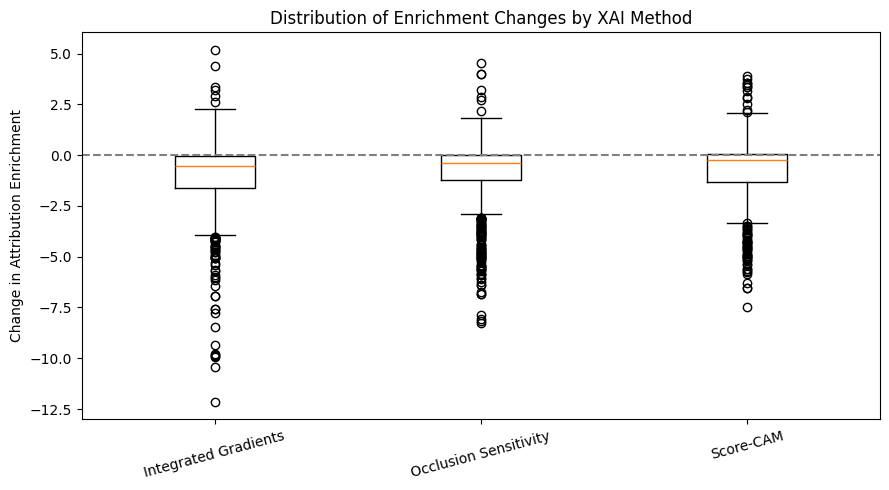

In [ ]:
methods = ["Integrated Gradients", "Occlusion Sensitivity", "Score-CAM"]

plot_data = [
    area_audit.loc[area_audit["method"] == method, "enrichment_change"].dropna().values
    for method in methods
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(plot_data, tick_labels=methods, showfliers=True)

ax.axhline(0, linestyle="--", color="gray")

ax.set_ylabel("Change in Attribution Enrichment")
ax.set_title("Distribution of Enrichment Changes by XAI Method")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


### Interpretation

All three XAI methods exhibited negative median changes in attribution enrichment following image corruption, indicating that reductions in attribution concentration within annotated opacity regions were common across the evaluated conditions.

Integrated Gradients showed the largest median decrease (-0.523), followed by Occlusion Sensitivity (-0.386) and Score-CAM (-0.235). Integrated Gradients also exhibited the widest interquartile range and the most extreme negative enrichment changes.

The distributions were asymmetric, with substantial negative outliers across all three methods. These observations suggest that mean enrichment changes may be influenced by a subset of evaluations exhibiting particularly large decreases.

Because enrichment change is calculated by dividing alignment change by annotated area fraction, the magnitude of these decreases may partly reflect differences in bounding-box coverage. Consequently, these results should be interpreted alongside the original alignment changes and the relationship between annotated area and enrichment change.

The comparisons are descriptive and do not establish a definitive robustness ranking among the XAI methods.



## 9. Relationship Between Bounding-Box Area and Enrichment Change

Attribution enrichment is calculated by dividing localization alignment by the annotated opacity area fraction. Consequently, images with smaller annotated regions may exhibit larger enrichment changes even when their absolute alignment changes are similar.

This section examines the relationship between bounding-box area fraction and the magnitude of enrichment change for each XAI method.

Spearman rank correlation and scatterplots are used to describe the association. Because each image contributes repeated measurements across corruption conditions, these results are descriptive rather than independent-sample statistical tests.

Any observed relationship must also be interpreted in light of the mathematical dependence of enrichment on bounding-box area.


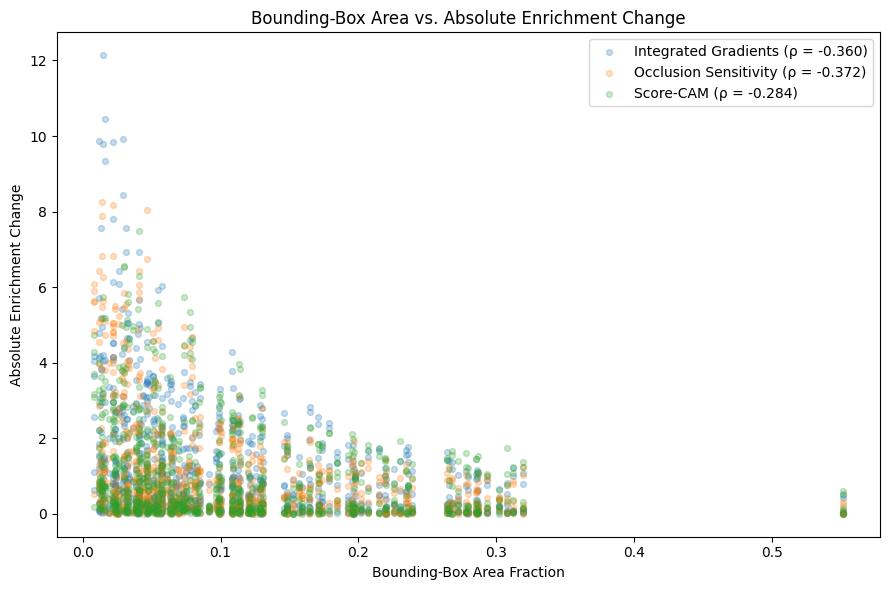

,method,spearman_rho,evaluations
0,Integrated Gradients,-0.3602,900
1,Occlusion Sensitivity,-0.3716,900
2,Score-CAM,-0.2844,900


In [ ]:
from scipy.stats import spearmanr

fig, ax = plt.subplots(figsize=(9, 6))

correlation_results = []

for method in methods:
    subset = area_audit[area_audit["method"] == method].copy()

    x = subset["box_area_fraction"]
    y = subset["enrichment_change"].abs()

    rho, _ = spearmanr(x, y, nan_policy="omit")

    correlation_results.append(
        {"method": method, "spearman_rho": rho, "evaluations": len(subset)}
    )

    ax.scatter(x, y, alpha=0.25, s=18, label=f"{method} (ρ = {rho:.3f})")

ax.set_xlabel("Bounding-Box Area Fraction")
ax.set_ylabel("Absolute Enrichment Change")
ax.set_title("Bounding-Box Area vs. Absolute Enrichment Change")
ax.legend()

plt.tight_layout()
plt.show()

correlation_df = pd.DataFrame(correlation_results)
display(correlation_df.round(4))


### Interpretation

All three XAI methods exhibited negative Spearman correlations between annotated opacity area fraction and the absolute magnitude of attribution enrichment change.

The correlations were -0.360 for Integrated Gradients, -0.372 for Occlusion Sensitivity, and -0.284 for Score-CAM.

The scatterplot showed that the largest absolute enrichment changes occurred predominantly in images with smaller annotated opacity regions. Images with larger annotated regions generally exhibited smaller enrichment changes.

This pattern is partly expected from the enrichment formula, which divides localization alignment change by the annotated area fraction. Consequently, the observed associations should not be interpreted as evidence that smaller opacity regions cause greater explanation instability.

These findings indicate that area-adjusted localization metrics require careful interpretation, particularly for images with small annotated regions. Both the original localization alignment change and area-adjusted enrichment change are retained for subsequent analyses.



## 10. Selection of Representative Cases for Attribution Visualization

This section identifies representative image–method–corruption combinations for visual inspection.

Cases are selected using the previously calculated explanation stability and localization alignment change metrics. The analysis considers stable explanations with substantial localization loss, stable explanations without substantial localization loss, and unstable explanations.

Case selection is performed using the saved numerical audit results. Selected attribution maps will subsequently be regenerated for visual comparison with the original chest X-rays and annotated opacity regions.

The selected cases are illustrative and are not intended to represent the full distribution of model behavior.


In [ ]:
print("Available audit columns:")
for column in area_audit.columns:
    print(" -", column)

print("\nMethods:")
print(area_audit["method"].unique())

print("\nCorruption conditions:")
display(area_audit[["corruption", "severity"]].drop_duplicates().reset_index(drop=True))

Available audit columns:
 - sop_uid
 - true_class
 - original_predicted_class
 - original_correct
 - corrupted_predicted_class
 - prediction_changed
 - corruption
 - severity
 - sigma
 - opacity_probability
 - explanation_similarity
 - localization_alignment
 - n_boxes
 - convergence_delta
 - method
 - original_alignment
 - alignment_change
 - high_stability
 - localization_loss
 - disagreement
 - box_area_fraction
 - attribution_enrichment
 - original_enrichment
 - enrichment_change

Methods:
['Integrated Gradients' 'Occlusion Sensitivity' 'Score-CAM']

Corruption conditions:


,corruption,severity
0,Blur,mild
1,Blur,moderate
2,Blur,severe
3,Noise,mild
4,Noise,moderate
5,Noise,severe


In [ ]:
# Work with correctly classified positive images
cases = area_audit[
    (area_audit["true_class"] == 1)
    & (area_audit["original_predicted_class"] == 1)
    & (area_audit["prediction_changed"] == False)
].copy()

# Define categories using the original audit thresholds
conditions = [
    (cases["explanation_similarity"] >= 0.80) & (cases["alignment_change"] <= -0.05),
    (cases["explanation_similarity"] >= 0.80) & (cases["alignment_change"] > -0.05),
    (cases["explanation_similarity"] < 0.80),
]

labels = [
    "Stable with localization loss",
    "Stable without substantial loss",
    "Unstable explanation",
]

cases["case_category"] = np.select(conditions, labels, default="Unclassified")

print("Available cases by category:")
display(
    cases["case_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="evaluations")
)

Available cases by category:


,category,evaluations
0,Unstable explanation,1347
1,Stable without substantial loss,785
2,Stable with localization loss,169


In [ ]:
selected_rows = []
used_images = set()

for category in labels:

    subset = cases[cases["case_category"] == category].copy()

    if subset.empty:
        print(f"No available cases for: {category}")
        continue

    # Identify typical alignment change within the category
    median_change = subset["alignment_change"].median()

    # Rank evaluations by closeness to category median
    subset["distance_from_median"] = (subset["alignment_change"] - median_change).abs()

    subset = subset.sort_values(["distance_from_median", "sop_uid", "method"])

    count = 0

    for _, row in subset.iterrows():

        if row["sop_uid"] in used_images:
            continue

        selected_rows.append(row)
        used_images.add(row["sop_uid"])
        count += 1

        if count == 2:
            break

selected_cases = pd.DataFrame(selected_rows).reset_index(drop=True)

display(
    selected_cases[
        [
            "case_category",
            "sop_uid",
            "method",
            "corruption",
            "severity",
            "explanation_similarity",
            "alignment_change",
            "box_area_fraction",
            "enrichment_change",
        ]
    ].round(4)
)

print("\nTotal selected cases:", len(selected_cases))
print("Unique images:", selected_cases["sop_uid"].nunique())

,case_category,sop_uid,method,corruption,severity,explanation_similarity,alignment_change,box_area_fraction,enrichment_change
0,Stable with localization loss,1.2.276.0.7230010.3.1.4.8323329.14010.15178743...,Occlusion Sensitivity,Blur,severe,0.8433,-0.0822,0.0161,-5.1021
1,Stable with localization loss,1.2.276.0.7230010.3.1.4.8323329.27461.15178744...,Occlusion Sensitivity,Blur,severe,0.8409,-0.0827,0.2681,-0.3085
2,Stable without substantial loss,1.2.276.0.7230010.3.1.4.8323329.21868.15178744...,Integrated Gradients,Blur,mild,0.8390,-0.0017,0.0477,-0.0359
3,Stable without substantial loss,1.2.276.0.7230010.3.1.4.8323329.6907.151787432...,Score-CAM,Blur,mild,0.9992,-0.0017,0.0635,-0.0267
4,Unstable explanation,1.2.276.0.7230010.3.1.4.8323329.4452.151787430...,Occlusion Sensitivity,Noise,moderate,0.4876,-0.0939,0.0138,-6.8191
5,Unstable explanation,1.2.276.0.7230010.3.1.4.8323329.21634.15178744...,Integrated Gradients,Blur,moderate,0.5631,-0.0939,0.0733,-1.2816



Total selected cases: 6
Unique images: 6



**Case-selection scope:** Representative cases were selected from evaluations involving correctly classified positive images for which the predicted class remained unchanged after corruption. This restricted subset contains 2,301 evaluations, rather than all 2,700 evaluations in the localization audit. The case categories describe this eligible subset only and should not be interpreted as prevalence estimates for the complete audit.



### Interpretation of Selected Cases

Six unique chest X-rays were selected for visual inspection, with two examples representing each explanation-stability category: stable explanations with localization loss, stable explanations without substantial localization loss, and unstable explanations.

The selected cases include all three XAI methods and both Gaussian blur and Gaussian noise corruptions. All six cases correspond to correctly classified positive images whose predicted class remained unchanged following corruption.

**Stable explanations with localization loss:** Two Occlusion Sensitivity cases under severe Gaussian blur exhibited high explanation similarity (0.8433 and 0.8409) despite decreases in localization alignment of approximately 0.082. These cases illustrate the possibility of maintaining high attribution rank similarity while losing attribution concentration within annotated opacity regions.

Although their alignment changes were nearly identical, their enrichment changes differed substantially (-5.1021 and -0.3085). This difference reflects their contrasting annotated area fractions (0.0161 and 0.2681), demonstrating the influence of bounding-box size on area-adjusted localization measurements.

**Stable explanations without substantial localization loss:** The Integrated Gradients and Score-CAM examples exhibited high explanation similarity (0.8390 and 0.9992) with minimal alignment changes of approximately -0.0017. These cases provide comparison examples in which attribution similarity remained high without substantial loss of localization alignment.

**Unstable explanations:** The selected Occlusion Sensitivity and Integrated Gradients examples exhibited lower explanation similarity (0.4876 and 0.5631), alongside alignment decreases of approximately 0.094. These cases provide examples for examining attribution changes when spatial similarity is relatively low.

Together, the six cases provide contrasting combinations of explanation stability, localization change, and annotated opacity area. Subsequent visualizations will examine whether the spatial attribution patterns are consistent with the numerical measurements.

Because the cases were selected for illustrative comparison rather than random sampling, they should not be interpreted as representative of the overall frequency or severity of explanation disagreement.



## 11. Attribution Visualization for Selected Cases

This section visually examines the six representative image–method–corruption combinations selected in Section 10.

For each case, the analysis will compare the original chest X-ray and its corrupted counterpart, the corresponding attribution maps, and the radiologist-annotated opacity regions.

Attribution maps will be regenerated using the trained ResNet-50 classifier and the same explanation settings used in the original audit. The explanation target will remain fixed to the original predicted class.

The visual comparisons will be interpreted alongside explanation similarity, localization alignment change, and attribution enrichment change.

The selected cases are illustrative examples and do not establish clinical reliability or explanation faithfulness.


In [17]:

%pip install -q pydicom


In [ ]:
import sys
import torch
import pydicom

# Update these paths to match your Google Drive folders
PROJECT_DIR = Path("/content/drive/MyDrive/XAI_project_Expo_1_folder")
DICOM_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/pnuemonia_challenge_dataset/mdai_rsna_project_x9N20BZa_images_2018-07-20-153330"
)

CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Models/resnet50_best.pth"
)

print("Checkpoint exists:", CHECKPOINT_PATH.is_file())


# Make the existing utility module importable
sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import (
    load_dicom,
    resize_image,
    medical_transform,
    prepare_corrupted_image,
    apply_gaussian_blur,
    apply_gaussian_noise,
    load_trained_model,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

assert DICOM_DIR.is_dir(), "DICOM directory not found."
assert CHECKPOINT_PATH.is_file(), "Model checkpoint not found."

model = load_trained_model(CHECKPOINT_PATH, device)

print("Model loaded successfully.")

Checkpoint exists: True
Device: cuda
Model loaded successfully.


In [ ]:
model = load_trained_model(CHECKPOINT_PATH, device)

print("Model loaded successfully.")
print("Device:", device)

Model loaded successfully.
Device: cuda



### 11.1. Model Checkpoint Verification

Before regenerating attribution maps, the loaded ResNet-50 checkpoint is checked against the original predictions recorded in the stability–localization audit.

This verification helps establish consistency between the trained classifier used for visualization and the classifier used in the original experiments.

The model is evaluated on an uncorrupted image using the same DICOM preprocessing and normalization pipeline as the earlier notebooks.


In [ ]:
# Load the dataset split metadata
SPLIT_PATH = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder/Data/model_dataset_split.csv"
)

assert SPLIT_PATH.is_file(), "Dataset split file not found."

split_df = pd.read_csv(SPLIT_PATH)

print("Dataset shape:", split_df.shape)

print("\nAvailable columns:")
print(split_df.columns.tolist())

print("\nFirst three rows:")
display(split_df.head(3))

Dataset shape: (29684, 8)

Available columns:
['study_uid', 'series_uid', 'sop_uid', 'final_label', 'target', 'image_path', 'patient_id', 'split']

First three rows:


,study_uid,series_uid,sop_uid,final_label,target,image_path,patient_id,split
0,1.2.276.0.7230010.3.1.2.8323329.20779.15178744...,1.2.276.0.7230010.3.1.3.8323329.20779.15178744...,1.2.276.0.7230010.3.1.4.8323329.20779.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,3129f567-c659-42f8-b4e1-8a5e3827b477,train
1,1.2.276.0.7230010.3.1.2.8323329.19863.15178744...,1.2.276.0.7230010.3.1.3.8323329.19863.15178744...,1.2.276.0.7230010.3.1.4.8323329.19863.15178744...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,2d37e84a-0e82-4fc4-b20a-de306a63ca67,validation
2,1.2.276.0.7230010.3.1.2.8323329.12963.15178743...,1.2.276.0.7230010.3.1.3.8323329.12963.15178743...,1.2.276.0.7230010.3.1.4.8323329.12963.15178743...,No Lung Opacity / Not Normal,0,/content/drive/MyDrive/XAI_project_Expo_1_fold...,309c2bb5-826b-4e7d-9bdb-9808d9450064,train


In [ ]:
# Match the six selected images with the dataset metadata
selected_uids = selected_cases["sop_uid"].astype(str).tolist()

matched_images = split_df[split_df["sop_uid"].astype(str).isin(selected_uids)].copy()

print("Selected images:", len(selected_uids))
print("Matching metadata records:", len(matched_images))

display(matched_images[["sop_uid", "image_path", "split", "target"]])

# Check that every selected image has exactly one metadata record
assert matched_images["sop_uid"].nunique() == len(selected_uids)
assert not matched_images["sop_uid"].duplicated().any()

# Create a dictionary mapping each image ID to its DICOM path
dicom_paths = {
    str(row["sop_uid"]): Path(row["image_path"]) for _, row in matched_images.iterrows()
}

# Check whether the files exist
for uid, path in dicom_paths.items():
    print(uid[-25:], "Found" if path.is_file() else "File missing")

print(
    "\nImages located:",
    sum(path.is_file() for path in dicom_paths.values()),
    "out of",
    len(selected_uids),
)

Selected images: 6
Matching metadata records: 6


,sop_uid,image_path,split,target
6037,1.2.276.0.7230010.3.1.4.8323329.21868.15178744...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1
10519,1.2.276.0.7230010.3.1.4.8323329.4452.151787430...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1
11591,1.2.276.0.7230010.3.1.4.8323329.21634.15178744...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1
26372,1.2.276.0.7230010.3.1.4.8323329.14010.15178743...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1
28544,1.2.276.0.7230010.3.1.4.8323329.27461.15178744...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1
29265,1.2.276.0.7230010.3.1.4.8323329.6907.151787432...,/content/drive/MyDrive/XAI_project_Expo_1_fold...,test,1


9.21868.1517874437.531158 Found
29.4452.1517874307.828827 Found
9.21634.1517874435.281707 Found
9.14010.1517874376.932819 Found
9.27461.1517874478.626741 Found
29.6907.1517874328.548199 Found

Images located: 6 out of 6


In [ ]:
# Verify the loaded model against the saved audit
model.eval()

prediction_records = []

for _, case in selected_cases.iterrows():
    uid = str(case["sop_uid"])

    # Load and preprocess the original DICOM
    image = load_dicom(dicom_paths[uid])
    image_tensor = medical_transform(image).unsqueeze(0).to(device)

    # Generate the model's positive-class probability
    with torch.no_grad():
        logit = model(image_tensor)
        probability = torch.sigmoid(logit).item()

    predicted_class = int(probability >= 0.5)
    saved_class = int(case["original_predicted_class"])

    prediction_records.append(
        {
            "sop_uid": uid,
            "method": case["method"],
            "saved_class": saved_class,
            "recomputed_class": predicted_class,
            "recomputed_probability": probability,
            "class_match": predicted_class == saved_class,
        }
    )

prediction_check = pd.DataFrame(prediction_records)

display(
    prediction_check[
        [
            "method",
            "saved_class",
            "recomputed_class",
            "recomputed_probability",
            "class_match",
        ]
    ].round(4)
)

print(
    "\nMatching predictions:",
    prediction_check["class_match"].sum(),
    "out of",
    len(prediction_check),
)

,method,saved_class,recomputed_class,recomputed_probability,class_match
0,Occlusion Sensitivity,1,1,0.8110,True
1,Occlusion Sensitivity,1,1,0.9739,True
2,Integrated Gradients,1,1,0.9617,True
3,Score-CAM,1,1,0.9859,True
4,Occlusion Sensitivity,1,1,0.7270,True
5,Integrated Gradients,1,1,0.9071,True



Matching predictions: 6 out of 6



### 11.2. Reconstructing Original and Corrupted Images

The selected DICOM images are loaded and resized to the model input resolution of 320 × 384 pixels.

For each selected case, the corresponding Gaussian blur or Gaussian noise corruption is reconstructed using the severity parameter recorded in the audit.

The original and corrupted images are prepared using the preprocessing functions from the previous experiments. This allows subsequent attribution maps to be generated under consistent input conditions.

The corruption parameters and image dimensions are verified before proceeding to explanation generation.


In [ ]:
# Prepare image pairs for the six selected cases
image_pairs = {}

for index, case in selected_cases.iterrows():
    uid = str(case["sop_uid"])

    original_image = resize_image(load_dicom(dicom_paths[uid]))

    corruption = case["corruption"]
    sigma = float(case["sigma"])

    if corruption == "Blur":
        corrupted_image = apply_gaussian_blur(original_image, sigma)

    elif corruption == "Noise":
        corrupted_image = apply_gaussian_noise(original_image, sigma, seed=42)

    else:
        raise ValueError(f"Unknown corruption: {corruption}")

    image_pairs[index] = {
        "original": original_image,
        "corrupted": corrupted_image,
        "case": case,
    }

    print(f"Case {index + 1}: " f"{corruption} ({case['severity']}), " f"sigma={sigma}")

print("\nPrepared image pairs:", len(image_pairs))

Case 1: Blur (severe), sigma=3.0
Case 2: Blur (severe), sigma=3.0
Case 3: Blur (mild), sigma=0.5
Case 4: Blur (mild), sigma=0.5
Case 5: Noise (moderate), sigma=0.05
Case 6: Blur (moderate), sigma=1.5

Prepared image pairs: 6


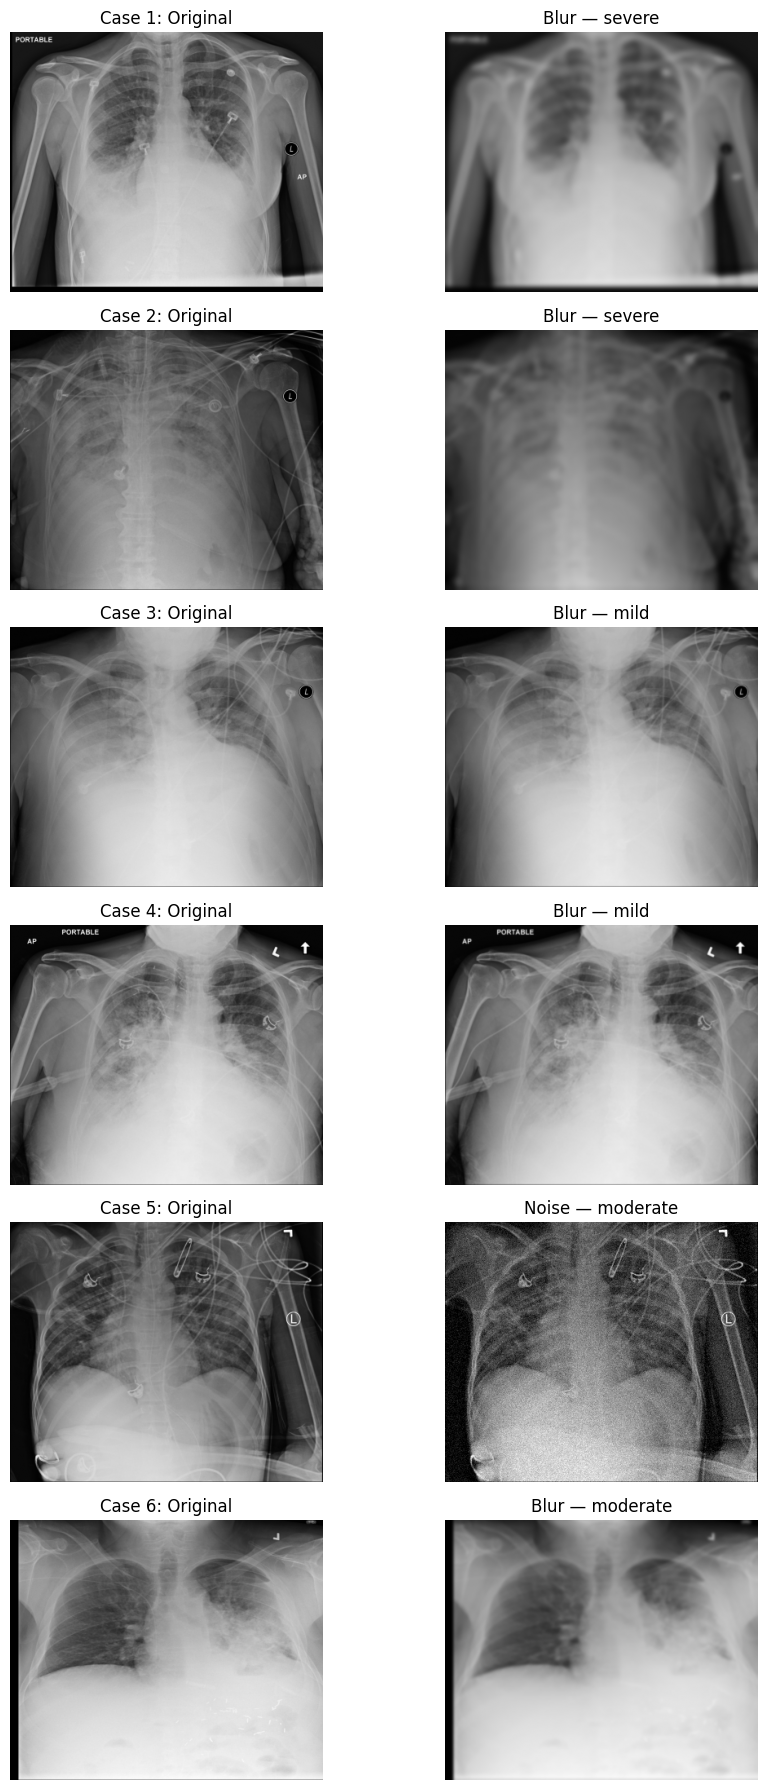

In [ ]:
fig, axes = plt.subplots(len(image_pairs), 2, figsize=(10, 3 * len(image_pairs)))

for index, pair in image_pairs.items():
    case = pair["case"]

    axes[index, 0].imshow(pair["original"], cmap="gray", vmin=0, vmax=1)

    axes[index, 0].set_title(f"Case {index + 1}: Original")

    axes[index, 1].imshow(pair["corrupted"], cmap="gray", vmin=0, vmax=1)

    axes[index, 1].set_title(f"{case['corruption']} — {case['severity']}")

    for ax in axes[index]:
        ax.axis("off")

plt.tight_layout()
plt.show()


### 11.3. Reusing the Original XAI Implementations

Attribution maps are regenerated using the explanation methods and parameters established in Notebook 06.

Integrated Gradients uses 32 integration steps and a normalized black-image baseline. Occlusion Sensitivity uses a 32 × 32 pixel window with stride 16. Score-CAM uses the final ResNet-50 layer-4 block as its target layer.

The original predicted class remains fixed as the explanation target for both the original and corrupted images.

Before generating all selected cases, the implementation will be checked on a single case by comparing its recalculated explanation similarity and localization alignment with the saved audit.

The Occlusion Sensitivity implementation is extracted from Notebook 05 to preserve consistency with the original explanation-generation procedure. This approach requires access to the source notebook and assumes that its function definition and dependencies remain compatible. The regenerated case-study measurements are compared with the saved audit to verify numerical consistency.


In [ ]:
import json
import ast

OCCLUSION_NOTEBOOK = PROJECT_DIR / "Python Notebooks" / "05_Occlusion_Sensitivity.ipynb"

print("Notebook exists:", OCCLUSION_NOTEBOOK.is_file())

assert OCCLUSION_NOTEBOOK.is_file(), "Check the location of Notebook 05."

with open(OCCLUSION_NOTEBOOK, "r", encoding="utf-8") as f:
    occlusion_notebook = json.load(f)

function_source = None

for cell in occlusion_notebook["cells"]:
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "def generate_occlusion_map(" not in source:
        continue

    tree = ast.parse(source)

    for node in tree.body:
        if isinstance(node, ast.FunctionDef) and node.name == "generate_occlusion_map":
            function_source = ast.get_source_segment(source, node)
            break

    if function_source is not None:
        break

assert function_source is not None, "Occlusion Sensitivity function not found."

# Review the extracted function before running it.
print(function_source[:2500])

Notebook exists: True
def generate_occlusion_map(
    image,
    model,
    device,
    target_class=1,
    window_size=32,
    stride=16,
    batch_size=32
):
    """
    Generate an Occlusion Sensitivity map for one grayscale image.

    image: resized grayscale image, shape (320, 384), range [0, 1]
    target_class: 1 for Lung Opacity, 0 for No Lung Opacity
    """

    model.eval()

    height, width = image.shape

    # Prepare original image
    original_tensor = prepare_corrupted_image(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        original_logit = model(original_tensor).flatten()[0].item()

    # Use the same class-specific target convention as previous XAI methods
    target_sign = 1 if target_class == 1 else -1
    original_score = target_sign * original_logit

    attribution_sum = np.zeros((height, width), dtype=np.float32)
    attribution_count = np.zeros((height, width), dtype=np.float32)

    # Include the image boundaries
    y_positions

In [ ]:
# Load the extracted Occlusion Sensitivity function
namespace = {
    "np": np,
    "torch": torch,
    "prepare_corrupted_image": prepare_corrupted_image,
}

exec(function_source, namespace)

generate_occlusion_map = namespace["generate_occlusion_map"]

print("Occlusion Sensitivity function loaded successfully.")
print("Function name:", generate_occlusion_map.__name__)

Occlusion Sensitivity function loaded successfully.
Function name: generate_occlusion_map


In [32]:

# Install the original explanation libraries if needed
%pip install -q captum grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from captum.attr import IntegratedGradients
from pytorch_grad_cam import ScoreCAM

# Match Notebook 06 settings
IG_STEPS = 32
IG_INTERNAL_BATCH_SIZE = 4

# Keep model parameters frozen, as in Notebook 06
model.eval()
for parameter in model.parameters():
    parameter.requires_grad_(False)


def forward_func(x):
    return model(x).squeeze(1)


def generate_ig_explanation(resized_image, target_class=1):
    x = prepare_corrupted_image(resized_image).unsqueeze(0).to(device)

    black_baseline = (
        prepare_corrupted_image(np.zeros_like(resized_image, dtype=np.float32))
        .unsqueeze(0)
        .to(device)
    )

    sign = 1 if target_class == 1 else -1

    def target_forward(inputs):
        return sign * forward_func(inputs)

    ig = IntegratedGradients(target_forward)

    attr, delta = ig.attribute(
        x,
        baselines=black_baseline,
        n_steps=IG_STEPS,
        internal_batch_size=IG_INTERNAL_BATCH_SIZE,
        return_convergence_delta=True,
    )

    signed_map = attr.detach().cpu().numpy()[0].sum(axis=0)

    return {
        "signed_map": signed_map,
        "magnitude_map": np.abs(signed_map),
        "convergence_delta": delta.item(),
    }


class PositiveClassTarget:
    def __call__(self, model_output):
        return model_output.reshape(-1)[0]


class NegativeClassTarget:
    def __call__(self, model_output):
        return -model_output.reshape(-1)[0]


def generate_scorecam_explanation(image, target_class):
    tensor = prepare_corrupted_image(image).unsqueeze(0).to(device)

    target = PositiveClassTarget() if target_class == 1 else NegativeClassTarget()

    with ScoreCAM(model=model, target_layers=[model.layer4[-1]]) as cam:
        cam.batch_size = 4

        heatmap = cam(input_tensor=tensor, targets=[target])[0].copy()

    return np.abs(heatmap)


print("Integrated Gradients ready.")
print("Score-CAM ready.")
print("Occlusion Sensitivity ready:", callable(generate_occlusion_map))
print("Device:", device)

Integrated Gradients ready.
Score-CAM ready.
Occlusion Sensitivity ready: True
Device: cuda


In [ ]:
from scipy.stats import spearmanr
from xai_utils import build_opacity_lookup, calculate_alignment

# Use the annotation records loaded earlier in Notebook 08
annotation_records = annotations["datasets"][0]["annotations"]
opacity_lookup = build_opacity_lookup(annotation_records)

# Case 1: Occlusion Sensitivity, severe Gaussian blur
case = selected_cases.iloc[0]
pair = image_pairs[0]

uid = str(case["sop_uid"])
target_class = int(case["original_predicted_class"])
boxes = opacity_lookup.get(uid, [])

assert case["method"] == "Occlusion Sensitivity"
assert len(boxes) > 0, "No opacity annotations found."

# Generate original explanation
original_map, _ = generate_occlusion_map(
    image=pair["original"],
    model=model,
    device=device,
    target_class=target_class,
    window_size=32,
    stride=16,
    batch_size=32,
)

# Generate corrupted explanation
corrupted_map, _ = generate_occlusion_map(
    image=pair["corrupted"],
    model=model,
    device=device,
    target_class=target_class,
    window_size=32,
    stride=16,
    batch_size=32,
)

# Match Notebook 06's magnitude-map convention
original_map = np.abs(np.asarray(original_map))
corrupted_map = np.abs(np.asarray(corrupted_map))

# Recalculate the metrics
recomputed_similarity = spearmanr(original_map.ravel(), corrupted_map.ravel()).statistic

recomputed_original_alignment = calculate_alignment(original_map, boxes)

recomputed_corrupted_alignment = calculate_alignment(corrupted_map, boxes)

recomputed_change = recomputed_corrupted_alignment - recomputed_original_alignment

# Compare with saved audit
validation = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case["explanation_similarity"],
            case["original_alignment"],
            case["localization_alignment"],
            case["alignment_change"],
        ],
        "Recomputed": [
            recomputed_similarity,
            recomputed_original_alignment,
            recomputed_corrupted_alignment,
            recomputed_change,
        ],
    }
)

validation["Absolute difference"] = (
    validation["Saved audit"] - validation["Recomputed"]
).abs()

display(validation.round(6))

if (validation["Absolute difference"] < 1e-3).all():
    print("PASS: Regenerated metrics match the saved audit.")
else:
    print("CHECK: Some metrics differ from the saved audit.")

,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.843307,0.843307,0.0
1,Original alignment,0.120686,0.120686,0.0
2,Corrupted alignment,0.038475,0.038475,0.0
3,Alignment change,-0.082211,-0.082211,0.0


PASS: Regenerated metrics match the saved audit.



### 11.4 Case 1: Stable Explanation with Localization Loss

The first selected case was regenerated using Occlusion Sensitivity under severe Gaussian blur.

The recalculated explanation similarity, original localization alignment, corrupted localization alignment, and alignment change matched the saved audit values.

The following visualization compares the original and corrupted chest X-rays alongside their corresponding attribution magnitude maps. Radiologist-annotated opacity bounding boxes are overlaid to support visual inspection of attribution concentration within the annotated regions.

The numerical measurements are used to contextualize the spatial attribution patterns. Visual inspection is descriptive and does not independently establish explanation faithfulness.


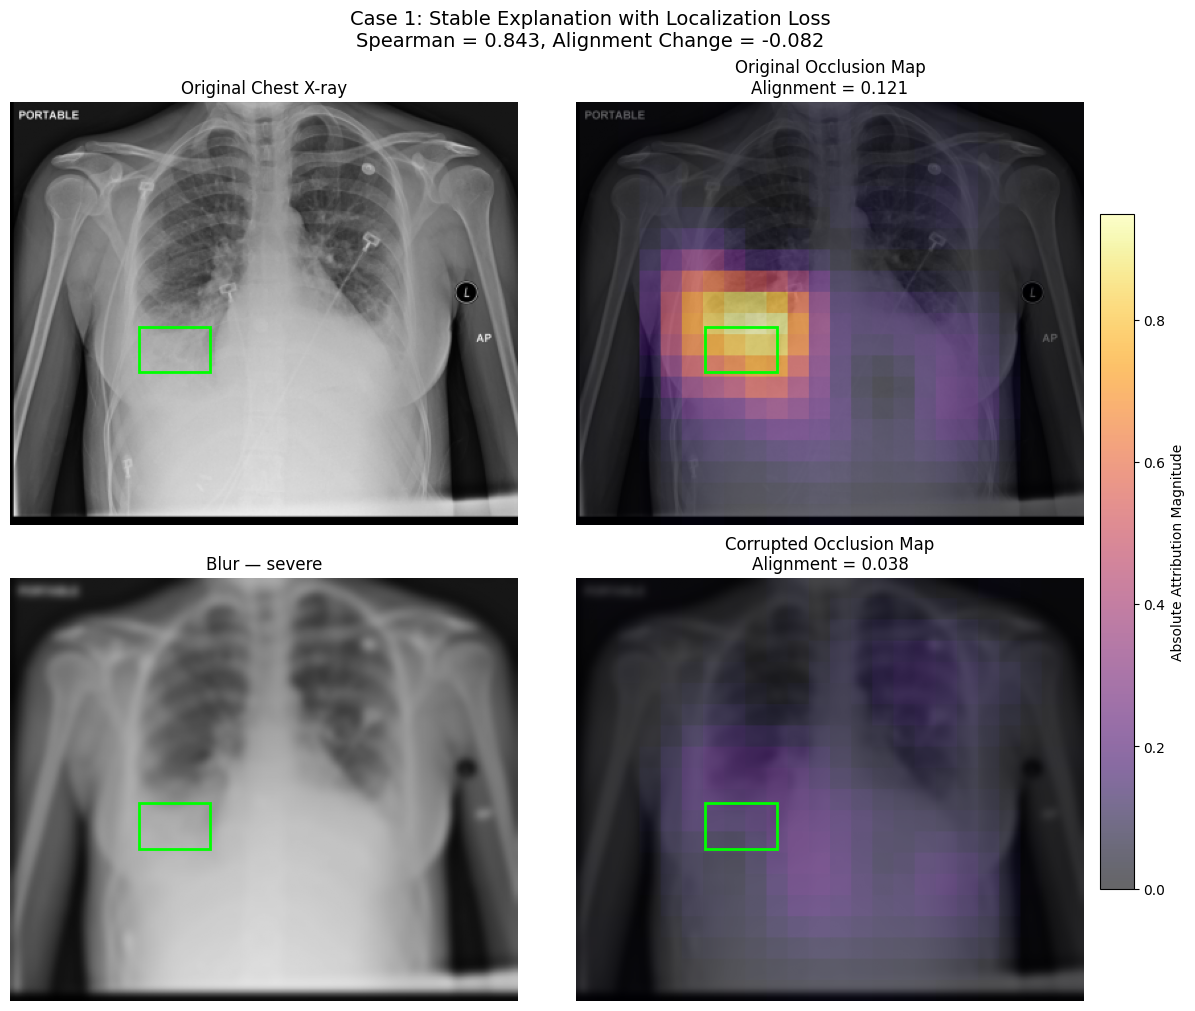

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# --------------------------------------------------
# 1. Function to draw radiologist opacity boxes
# --------------------------------------------------


def draw_opacity_boxes(ax, boxes, image_shape):
    height, width = image_shape

    for record in boxes:
        box = record["data"]

        scale_x = width / record["width"]
        scale_y = height / record["height"]

        x = box["x"] * scale_x
        y = box["y"] * scale_y
        w = box["width"] * scale_x
        h = box["height"] * scale_y

        rectangle = Rectangle(
            (x, y), w, h, linewidth=2, edgecolor="lime", facecolor="none", zorder=10
        )

        ax.add_patch(rectangle)


# --------------------------------------------------
# 2. Establish a shared attribution color scale
# --------------------------------------------------

shared_vmin = 0.0

shared_vmax = max(float(np.max(original_map)), float(np.max(corrupted_map)))

assert shared_vmax > 0, "Attribution maps contain no positive magnitude."


# --------------------------------------------------
# 3. Create the four-panel visualization
# --------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape = pair["original"].shape

# Panel 1: Original chest X-ray
axes[0, 0].imshow(pair["original"], cmap="gray", vmin=0, vmax=1)

draw_opacity_boxes(axes[0, 0], boxes, image_shape)

axes[0, 0].set_title("Original Chest X-ray")


# Panel 2: Original attribution heatmap
axes[0, 1].imshow(pair["original"], cmap="gray", vmin=0, vmax=1)

heatmap_original = axes[0, 1].imshow(
    original_map, cmap="inferno", alpha=0.6, vmin=shared_vmin, vmax=shared_vmax
)

draw_opacity_boxes(axes[0, 1], boxes, image_shape)

axes[0, 1].set_title(
    "Original Occlusion Map\n" f"Alignment = {recomputed_original_alignment:.3f}"
)


# Panel 3: Corrupted chest X-ray
axes[1, 0].imshow(pair["corrupted"], cmap="gray", vmin=0, vmax=1)

draw_opacity_boxes(axes[1, 0], boxes, image_shape)

axes[1, 0].set_title(f"{case['corruption']} — {case['severity']}")


# Panel 4: Corrupted attribution heatmap
axes[1, 1].imshow(pair["corrupted"], cmap="gray", vmin=0, vmax=1)

heatmap_corrupted = axes[1, 1].imshow(
    corrupted_map, cmap="inferno", alpha=0.6, vmin=shared_vmin, vmax=shared_vmax
)

draw_opacity_boxes(axes[1, 1], boxes, image_shape)

axes[1, 1].set_title(
    "Corrupted Occlusion Map\n" f"Alignment = {recomputed_corrupted_alignment:.3f}"
)


# --------------------------------------------------
# 4. Format the figure
# --------------------------------------------------

for ax in axes.flat:
    ax.axis("off")

# Shared color bar for both attribution maps
colorbar = fig.colorbar(heatmap_original, ax=axes[:, 1], shrink=0.75, pad=0.03)

colorbar.set_label("Absolute Attribution Magnitude")

fig.suptitle(
    "Case 1: Stable Explanation with Localization Loss\n"
    f"Spearman = {recomputed_similarity:.3f}, "
    f"Alignment Change = {recomputed_change:.3f}",
    fontsize=14,
)

plt.show()

### Case 1 Interpretation: Stable Explanation with Localization Loss

Case 1 examines an Occlusion Sensitivity explanation for a correctly classified lung-opacity image subjected to severe Gaussian blur (σ = 3.0). The regenerated attribution maps reproduced the numerical measurements from the original audit.

**Original explanation:** The attribution map shows a concentrated region of high attribution near the radiologist-annotated opacity bounding box. However, much of the strongest attribution extends beyond the annotated region. The original localization alignment is 0.1207, indicating that approximately 12.07% of total attribution magnitude falls within the annotated opacity region.

**Corrupted explanation:** Following severe Gaussian blur, the attribution map exhibits lower overall attribution magnitude and a more diffuse spatial pattern. Under the shared color scale, the corrupted map appears substantially darker than the original. Localization alignment decreases to 0.0385, indicating that only 3.85% of total attribution magnitude remains within the annotated opacity region.

**Stability–localization disagreement:** Despite these changes, Spearman rank correlation between the original and corrupted attribution maps remains relatively high (ρ = 0.8433). Localization alignment decreases by 0.0822 (8.22 percentage points), representing approximately a 68% relative reduction.

**Interpretation:** This case demonstrates that relatively high global attribution rank similarity can coexist with reduced attribution concentration within clinically annotated regions. It also illustrates why explanation similarity and localization alignment capture different aspects of explanation behavior under image corruption.

**Limitations:** The visualization uses a shared attribution color scale to support comparison of attribution magnitudes. However, visual inspection alone cannot establish explanation faithfulness, and radiologist-annotated opacity regions do not necessarily capture every image feature relevant to the model's prediction.


### 11.5 Case 2

Case 2 examines a lung-opacity image subjected to severe Gaussian blur (σ = 3.0), using Occlusion Sensitivity.

Unlike Case 1, the annotated opacity regions cover a substantially larger fraction of the image (approximately 26.81%). This case provides an opportunity to examine stability–localization disagreement under different bounding-box coverage.

The original and corrupted attribution maps are regenerated and compared against the saved audit before visualization.


In [ ]:
# Select Case 2
case2 = selected_cases.iloc[1]
pair2 = image_pairs[1]

uid2 = str(case2["sop_uid"])
target_class2 = int(case2["original_predicted_class"])
boxes2 = opacity_lookup.get(uid2, [])

assert case2["method"] == "Occlusion Sensitivity"
assert len(boxes2) > 0

# Generate attribution maps
original_map2, _ = generate_occlusion_map(
    image=pair2["original"],
    model=model,
    device=device,
    target_class=target_class2,
    window_size=32,
    stride=16,
    batch_size=32,
)

corrupted_map2, _ = generate_occlusion_map(
    image=pair2["corrupted"],
    model=model,
    device=device,
    target_class=target_class2,
    window_size=32,
    stride=16,
    batch_size=32,
)

original_map2 = np.abs(np.asarray(original_map2))
corrupted_map2 = np.abs(np.asarray(corrupted_map2))

# Recalculate metrics
similarity2 = spearmanr(original_map2.ravel(), corrupted_map2.ravel()).statistic

original_alignment2 = calculate_alignment(original_map2, boxes2)

corrupted_alignment2 = calculate_alignment(corrupted_map2, boxes2)

alignment_change2 = corrupted_alignment2 - original_alignment2

# Compare with saved audit
validation2 = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case2["explanation_similarity"],
            case2["original_alignment"],
            case2["localization_alignment"],
            case2["alignment_change"],
        ],
        "Recomputed": [
            similarity2,
            original_alignment2,
            corrupted_alignment2,
            alignment_change2,
        ],
    }
)

validation2["Absolute difference"] = (
    validation2["Saved audit"] - validation2["Recomputed"]
).abs()

display(validation2.round(6))

if (validation2["Absolute difference"] < 1e-3).all():
    print("PASS: Case 2 metrics match the saved audit.")
else:
    print("CHECK: Case 2 metrics differ from the saved audit.")

,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.840854,0.840854,0.0
1,Original alignment,0.639810,0.639810,0.0
2,Corrupted alignment,0.557113,0.557113,0.0
3,Alignment change,-0.082697,-0.082697,0.0


PASS: Case 2 metrics match the saved audit.


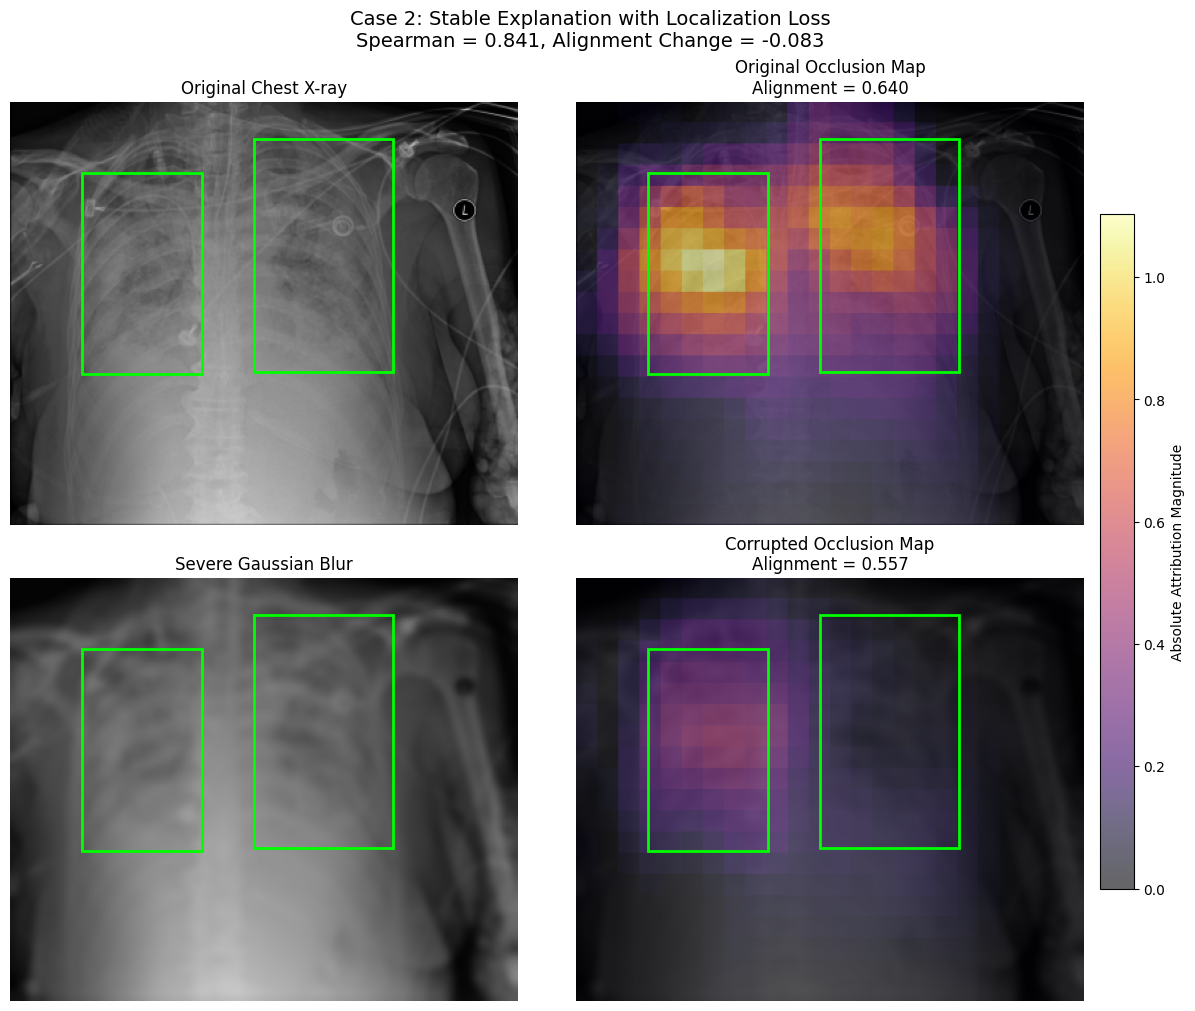

In [ ]:
# Shared color scale for Case 2
shared_vmin2 = 0.0
shared_vmax2 = max(float(np.max(original_map2)), float(np.max(corrupted_map2)))

assert shared_vmax2 > 0

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape2 = pair2["original"].shape

# Original X-ray
axes[0, 0].imshow(pair2["original"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[0, 0], boxes2, image_shape2)
axes[0, 0].set_title("Original Chest X-ray")

# Original attribution
axes[0, 1].imshow(pair2["original"], cmap="gray", vmin=0, vmax=1)
heatmap2 = axes[0, 1].imshow(
    original_map2, cmap="inferno", alpha=0.6, vmin=shared_vmin2, vmax=shared_vmax2
)
draw_opacity_boxes(axes[0, 1], boxes2, image_shape2)
axes[0, 1].set_title(f"Original Occlusion Map\nAlignment = {original_alignment2:.3f}")

# Corrupted X-ray
axes[1, 0].imshow(pair2["corrupted"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[1, 0], boxes2, image_shape2)
axes[1, 0].set_title("Severe Gaussian Blur")

# Corrupted attribution
axes[1, 1].imshow(pair2["corrupted"], cmap="gray", vmin=0, vmax=1)
axes[1, 1].imshow(
    corrupted_map2, cmap="inferno", alpha=0.6, vmin=shared_vmin2, vmax=shared_vmax2
)
draw_opacity_boxes(axes[1, 1], boxes2, image_shape2)
axes[1, 1].set_title(f"Corrupted Occlusion Map\nAlignment = {corrupted_alignment2:.3f}")

for ax in axes.flat:
    ax.axis("off")

colorbar = fig.colorbar(heatmap2, ax=axes[:, 1], shrink=0.75, pad=0.03)
colorbar.set_label("Absolute Attribution Magnitude")

fig.suptitle(
    "Case 2: Stable Explanation with Localization Loss\n"
    f"Spearman = {similarity2:.3f}, "
    f"Alignment Change = {alignment_change2:.3f}",
    fontsize=14,
)

plt.show()

### Case 2 Interpretation: Stable Explanation with Localization Loss

Case 2 examines an Occlusion Sensitivity explanation for a correctly classified lung-opacity image subjected to severe Gaussian blur (σ = 3.0). The radiologist-annotated opacity regions cover approximately 26.81% of the image.

**Original explanation:** The attribution map shows prominent regions of high attribution across both lungs, with substantial overlap between the attribution patterns and the annotated opacity regions. The original localization alignment is 0.6398, indicating that 63.98% of total attribution magnitude falls within the bounding boxes.

**Corrupted explanation:** Following severe Gaussian blur, the overall attribution magnitude decreases visibly under the shared color scale. The attribution becomes less prominent across both annotated regions, particularly in the right side of the displayed image. Localization alignment decreases to 0.5571, indicating that 55.71% of attribution magnitude remains within the annotated regions.

**Stability–localization disagreement:** Despite these changes, the explanation similarity remains relatively high (Spearman ρ = 0.8409). Localization alignment decreases by 0.0827, equivalent to 8.27 percentage points or approximately 12.9% relative to the original alignment.

**Comparison with Case 1:** Although Cases 1 and 2 exhibit similar absolute alignment decreases, their initial alignment and annotation coverage differ substantially. Case 2 retains considerably more attribution within annotated regions after corruption. This highlights the importance of considering baseline localization and bounding-box coverage when interpreting stability–localization disagreement.

**Limitations:** The visualizations use a shared color scale within the case. Attribution alignment measures spatial overlap with radiologist annotations, not explanation faithfulness. Additionally, differences in annotation coverage can influence alignment and area-adjusted enrichment measurements.


### 11.6 Case 3: Stable Explanation Without Substantial Localization Loss

Case 3 examines Integrated Gradients explanations for a correctly classified lung-opacity image subjected to mild Gaussian blur (σ = 0.5).

Unlike the preceding disagreement cases, this case exhibits relatively high explanation similarity without a substantial decrease in localization alignment.

The original and corrupted attribution maps are regenerated using the same Integrated Gradients configuration as the original experiment. Their explanation similarity and localization measurements are compared against the saved audit before visualization.


In [ ]:
# Select Case 3
case3 = selected_cases.iloc[2]
pair3 = image_pairs[2]

uid3 = str(case3["sop_uid"])
target_class3 = int(case3["original_predicted_class"])
boxes3 = opacity_lookup.get(uid3, [])

assert case3["method"] == "Integrated Gradients"
assert len(boxes3) > 0

# Generate original and corrupted IG explanations
original_ig3 = generate_ig_explanation(pair3["original"], target_class=target_class3)

corrupted_ig3 = generate_ig_explanation(pair3["corrupted"], target_class=target_class3)

# Extract attribution magnitude maps
original_map3 = np.asarray(original_ig3["magnitude_map"])

corrupted_map3 = np.asarray(corrupted_ig3["magnitude_map"])

# Recalculate explanation similarity
similarity3 = spearmanr(original_map3.ravel(), corrupted_map3.ravel()).statistic

# Recalculate localization alignment
original_alignment3 = calculate_alignment(original_map3, boxes3)

corrupted_alignment3 = calculate_alignment(corrupted_map3, boxes3)

alignment_change3 = corrupted_alignment3 - original_alignment3

# Compare against saved audit
validation3 = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case3["explanation_similarity"],
            case3["original_alignment"],
            case3["localization_alignment"],
            case3["alignment_change"],
        ],
        "Recomputed": [
            similarity3,
            original_alignment3,
            corrupted_alignment3,
            alignment_change3,
        ],
    }
)

validation3["Absolute difference"] = (
    validation3["Saved audit"] - validation3["Recomputed"]
).abs()

display(validation3.round(6))

if (validation3["Absolute difference"] < 1e-3).all():
    print("PASS: Case 3 metrics match the saved audit.")
else:
    print("CHECK: Case 3 metrics differ from the saved audit.")

print("\nOriginal IG convergence delta:", original_ig3["convergence_delta"])

print("Corrupted IG convergence delta:", corrupted_ig3["convergence_delta"])

,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.839011,0.839011,0.0
1,Original alignment,0.033930,0.033930,0.0
2,Corrupted alignment,0.032219,0.032219,0.0
3,Alignment change,-0.001711,-0.001711,0.0


PASS: Case 3 metrics match the saved audit.

Original IG convergence delta: -0.018720149993896484
Corrupted IG convergence delta: -0.034682512283325195


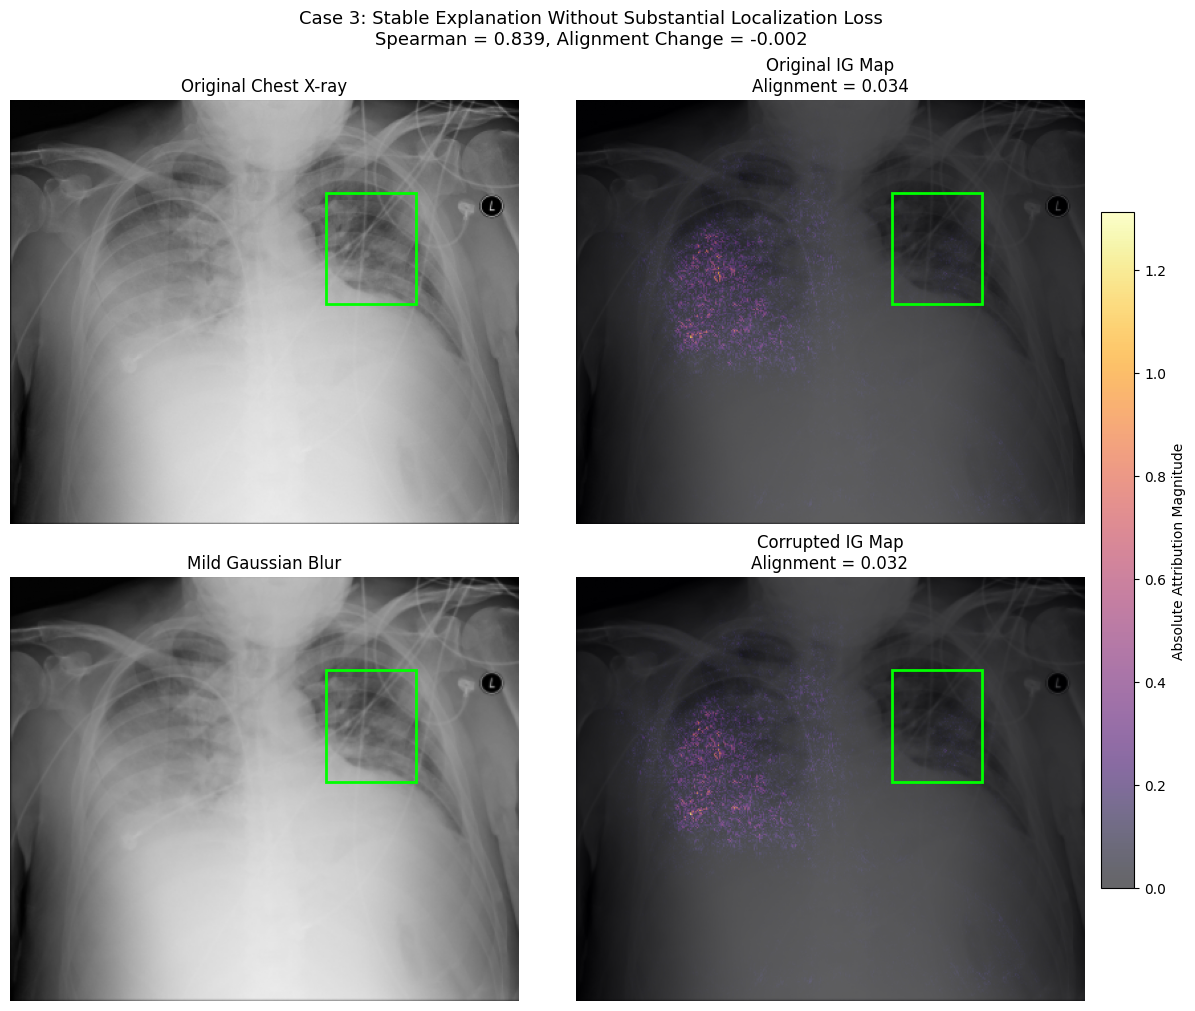

In [ ]:
# Case 3: Integrated Gradients visualization

shared_vmin3 = 0.0
shared_vmax3 = max(float(np.max(original_map3)), float(np.max(corrupted_map3)))

assert shared_vmax3 > 0

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape3 = pair3["original"].shape

# Panel 1: Original chest X-ray
axes[0, 0].imshow(pair3["original"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[0, 0], boxes3, image_shape3)
axes[0, 0].set_title("Original Chest X-ray")

# Panel 2: Original Integrated Gradients map
axes[0, 1].imshow(pair3["original"], cmap="gray", vmin=0, vmax=1)

heatmap3 = axes[0, 1].imshow(
    original_map3, cmap="inferno", alpha=0.6, vmin=shared_vmin3, vmax=shared_vmax3
)

draw_opacity_boxes(axes[0, 1], boxes3, image_shape3)

axes[0, 1].set_title(f"Original IG Map\n" f"Alignment = {original_alignment3:.3f}")

# Panel 3: Mild Gaussian blur
axes[1, 0].imshow(pair3["corrupted"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[1, 0], boxes3, image_shape3)
axes[1, 0].set_title("Mild Gaussian Blur")

# Panel 4: Corrupted Integrated Gradients map
axes[1, 1].imshow(pair3["corrupted"], cmap="gray", vmin=0, vmax=1)

axes[1, 1].imshow(
    corrupted_map3, cmap="inferno", alpha=0.6, vmin=shared_vmin3, vmax=shared_vmax3
)

draw_opacity_boxes(axes[1, 1], boxes3, image_shape3)

axes[1, 1].set_title(f"Corrupted IG Map\n" f"Alignment = {corrupted_alignment3:.3f}")

# Formatting
for ax in axes.flat:
    ax.axis("off")

colorbar = fig.colorbar(heatmap3, ax=axes[:, 1], shrink=0.75, pad=0.03)
colorbar.set_label("Absolute Attribution Magnitude")

fig.suptitle(
    "Case 3: Stable Explanation Without Substantial Localization Loss\n"
    f"Spearman = {similarity3:.3f}, "
    f"Alignment Change = {alignment_change3:.3f}",
    fontsize=13,
)

plt.show()


### Case 3 Interpretation: Stable Explanation Without Substantial Localization Loss

Case 3 examines an Integrated Gradients explanation for a correctly classified lung-opacity image subjected to mild Gaussian blur (σ = 0.5).

**Original explanation:** The attribution map shows scattered regions of relatively high attribution, primarily outside the radiologist-annotated opacity bounding box. The original localization alignment is 0.0339, indicating that approximately 3.39% of total attribution magnitude falls within the annotated region. The bounding box covers approximately 4.77% of the image, resulting in an original attribution enrichment of approximately 0.71.

**Corrupted explanation:** Following mild Gaussian blur, the attribution pattern remains visually similar to the original. Localization alignment decreases slightly to 0.0322, corresponding to a decrease of approximately 0.17 percentage points.

**Explanation stability:** Spearman rank correlation remains relatively high (ρ = 0.8390), while localization alignment changes only minimally. Therefore, this case satisfies the criteria for a stable explanation without substantial localization loss.

**Interpretation:** Although the explanation remains relatively stable under mild corruption, its baseline localization alignment is low. This illustrates that preserving localization does not necessarily imply strong localization within clinically annotated regions. Explanation stability and localization quality should therefore be evaluated separately.

**Limitations:** Integrated Gradients attribution magnitudes are displayed using a shared color scale within this case. The magnitude maps do not preserve the direction of individual feature contributions, and overlap with radiologist annotations does not independently establish explanation faithfulness.



### 11.7. Case 4: Score-CAM Under Mild Gaussian Blur

Case 4 examines a Score-CAM explanation for a correctly classified lung-opacity image subjected to mild Gaussian blur (σ = 0.5).

The saved audit indicates very high explanation similarity with minimal localization change. The original and corrupted attribution maps are regenerated to validate these measurements before visual comparison.


In [ ]:
import inspect

print("Score-CAM function signature:")
print(inspect.signature(generate_scorecam_explanation))

print("\nFunction source:")
print(inspect.getsource(generate_scorecam_explanation))

Score-CAM function signature:
(image, target_class)

Function source:
def generate_scorecam_explanation(image, target_class):
    tensor = (
        prepare_corrupted_image(image)
        .unsqueeze(0)
        .to(device)
    )

    target = (
        PositiveClassTarget()
        if target_class == 1
        else NegativeClassTarget()
    )

    with ScoreCAM(
        model=model,
        target_layers=[model.layer4[-1]]
    ) as cam:
        cam.batch_size = 4

        heatmap = cam(
            input_tensor=tensor,
            targets=[target]
        )[0].copy()

    return np.abs(heatmap)



In [ ]:
# --------------------------------------------------
# 1. Select Case 4
# --------------------------------------------------

case4 = selected_cases.iloc[3]
pair4 = image_pairs[3]

uid4 = str(case4["sop_uid"])
target_class4 = int(case4["original_predicted_class"])
boxes4 = opacity_lookup.get(uid4, [])

assert case4["method"] == "Score-CAM"
assert case4["corruption"] == "Blur"
assert case4["severity"] == "mild"
assert len(boxes4) > 0

print("Method:", case4["method"])
print("Corruption:", case4["corruption"])
print("Severity:", case4["severity"])
print("Target class:", target_class4)


# --------------------------------------------------
# 2. Regenerate Score-CAM attribution maps
# --------------------------------------------------

original_map4 = generate_scorecam_explanation(
    image=pair4["original"], target_class=target_class4
)

corrupted_map4 = generate_scorecam_explanation(
    image=pair4["corrupted"], target_class=target_class4
)

original_map4 = np.abs(np.asarray(original_map4))
corrupted_map4 = np.abs(np.asarray(corrupted_map4))

assert original_map4.shape == pair4["original"].shape
assert corrupted_map4.shape == pair4["corrupted"].shape

print("Original map shape:", original_map4.shape)
print("Corrupted map shape:", corrupted_map4.shape)


# --------------------------------------------------
# 3. Recalculate explanation similarity
# --------------------------------------------------

similarity4 = spearmanr(original_map4.ravel(), corrupted_map4.ravel()).statistic


# --------------------------------------------------
# 4. Recalculate localization alignment
# --------------------------------------------------

original_alignment4 = calculate_alignment(original_map4, boxes4)

corrupted_alignment4 = calculate_alignment(corrupted_map4, boxes4)

alignment_change4 = corrupted_alignment4 - original_alignment4


# --------------------------------------------------
# 5. Compare against the saved audit
# --------------------------------------------------

validation4 = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case4["explanation_similarity"],
            case4["original_alignment"],
            case4["localization_alignment"],
            case4["alignment_change"],
        ],
        "Recomputed": [
            similarity4,
            original_alignment4,
            corrupted_alignment4,
            alignment_change4,
        ],
    }
)

validation4["Absolute difference"] = (
    validation4["Saved audit"] - validation4["Recomputed"]
).abs()

display(validation4.round(6))


# --------------------------------------------------
# 6. Validation result
# --------------------------------------------------

tolerance = 1e-3

if (
    np.isfinite(validation4["Recomputed"]).all()
    and (validation4["Absolute difference"] < tolerance).all()
):
    print("PASS: Case 4 metrics match the saved audit.")
else:
    print("CHECK: Case 4 metrics differ from the saved audit.")

Method: Score-CAM
Corruption: Blur
Severity: mild
Target class: 1


100%|██████████| 512/512 [00:22<00:00, 22.61it/s]


Original map shape: (320, 384)
Corrupted map shape: (320, 384)


,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.999247,0.999247,0.0
1,Original alignment,0.277369,0.277369,0.0
2,Corrupted alignment,0.275675,0.275675,0.0
3,Alignment change,-0.001694,-0.001694,0.0


PASS: Case 4 metrics match the saved audit.


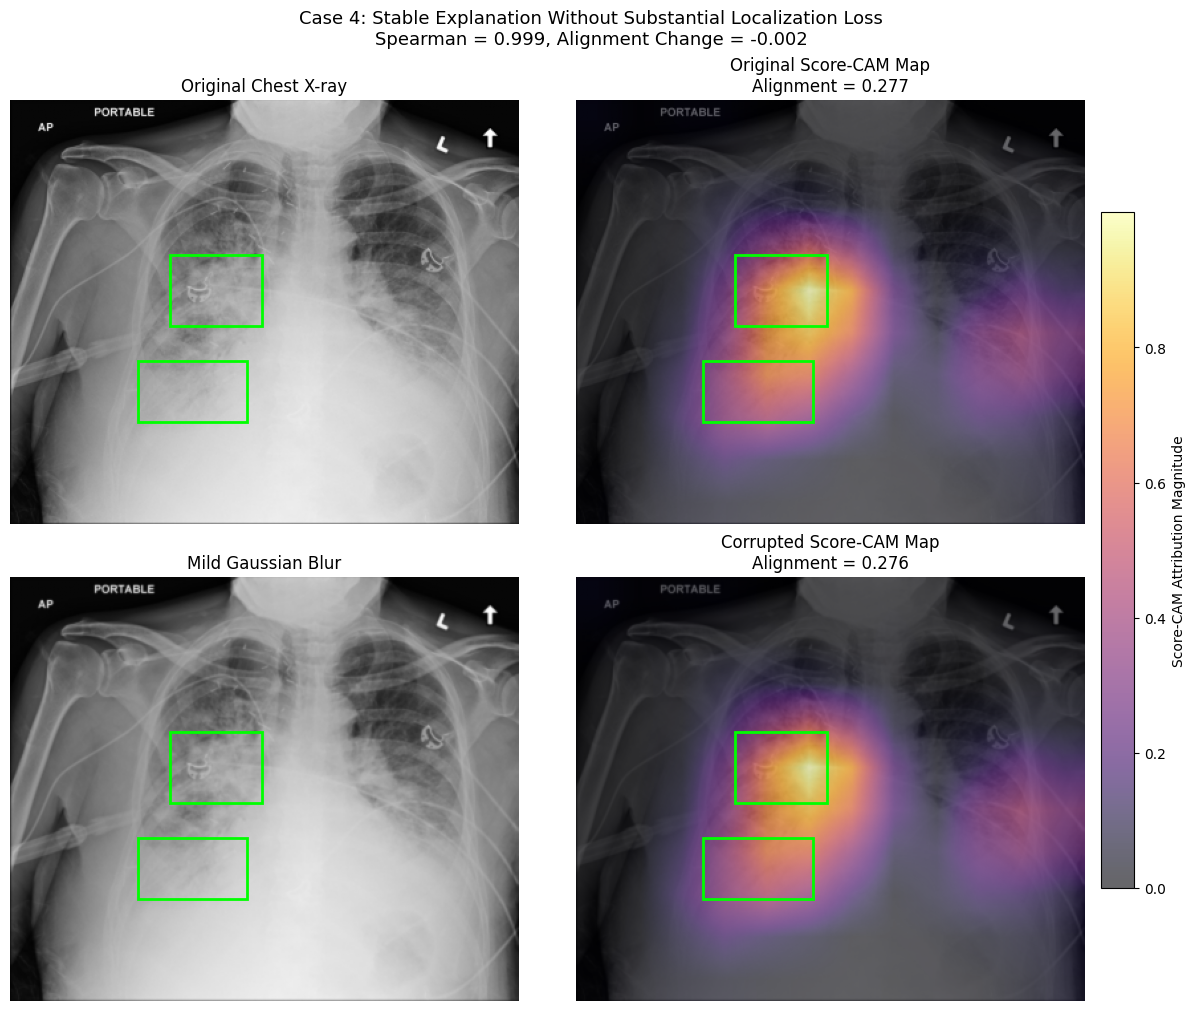

In [ ]:
# --------------------------------------------------
# Case 4: Score-CAM visualization
# --------------------------------------------------

shared_vmin4 = 0.0
shared_vmax4 = max(float(np.max(original_map4)), float(np.max(corrupted_map4)))

assert shared_vmax4 > 0

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape4 = pair4["original"].shape

# Panel 1: Original chest X-ray
axes[0, 0].imshow(pair4["original"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[0, 0], boxes4, image_shape4)
axes[0, 0].set_title("Original Chest X-ray")

# Panel 2: Original Score-CAM map
axes[0, 1].imshow(pair4["original"], cmap="gray", vmin=0, vmax=1)

heatmap4 = axes[0, 1].imshow(
    original_map4, cmap="inferno", alpha=0.6, vmin=shared_vmin4, vmax=shared_vmax4
)

draw_opacity_boxes(axes[0, 1], boxes4, image_shape4)
axes[0, 1].set_title(
    f"Original Score-CAM Map\n" f"Alignment = {original_alignment4:.3f}"
)

# Panel 3: Mild Gaussian blur
axes[1, 0].imshow(pair4["corrupted"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[1, 0], boxes4, image_shape4)
axes[1, 0].set_title("Mild Gaussian Blur")

# Panel 4: Corrupted Score-CAM map
axes[1, 1].imshow(pair4["corrupted"], cmap="gray", vmin=0, vmax=1)

axes[1, 1].imshow(
    corrupted_map4, cmap="inferno", alpha=0.6, vmin=shared_vmin4, vmax=shared_vmax4
)

draw_opacity_boxes(axes[1, 1], boxes4, image_shape4)
axes[1, 1].set_title(
    f"Corrupted Score-CAM Map\n" f"Alignment = {corrupted_alignment4:.3f}"
)

# Formatting
for ax in axes.flat:
    ax.axis("off")

colorbar = fig.colorbar(heatmap4, ax=axes[:, 1], shrink=0.75, pad=0.03)

colorbar.set_label("Score-CAM Attribution Magnitude")

fig.suptitle(
    "Case 4: Stable Explanation Without Substantial Localization Loss\n"
    f"Spearman = {similarity4:.3f}, "
    f"Alignment Change = {alignment_change4:.3f}",
    fontsize=13,
)

plt.show()


### Case 4 Interpretation: Highly Stable Score-CAM Explanation

Case 4 examines a Score-CAM explanation for a correctly classified lung-opacity image subjected to mild Gaussian blur (σ = 0.5).

**Original explanation:** The attribution map shows a prominent region of high attribution overlapping the upper radiologist-annotated opacity box, with additional attribution around the lower box and elsewhere in the image. The original localization alignment is 0.2774, indicating that approximately 27.74% of attribution magnitude falls within the annotated regions.

**Corrupted explanation:** Following mild Gaussian blur, the attribution pattern remains visually similar to the original. The strongest attribution regions retain approximately the same spatial distribution, and localization alignment decreases only slightly to 0.2757.

**Explanation stability:** Spearman rank correlation is 0.9992, indicating exceptionally high similarity in pixel attribution rankings. Localization alignment decreases by approximately 0.17 percentage points.

**Interpretation:** This case illustrates a Score-CAM explanation whose spatial attribution pattern and localization alignment are largely preserved under mild image corruption. Unlike the disagreement cases, high explanation similarity is accompanied by minimal localization loss. The original attribution enrichment of approximately 4.37 indicates greater attribution concentration within the annotated regions than would be expected under a spatially uniform attribution distribution.

**Limitations:** These findings describe one selected image-corruption pair and should not be generalized to all Score-CAM explanations. Attribution overlap with radiologist annotations does not independently establish explanation faithfulness.



### 11.8. Case 5: Unstable Explanation with Localization Loss

Case 5 examines an Occlusion Sensitivity explanation for a correctly classified lung-opacity image subjected to moderate Gaussian noise (σ = 0.05).

The saved audit indicates relatively low explanation similarity and a substantial decrease in localization alignment. Unlike Cases 1 and 2, where localization loss occurred despite high explanation similarity, this case represents localization loss accompanied by explanation instability.

The original and corrupted attribution maps are regenerated using the original predicted class as the fixed explanation target. Their numerical measurements are validated against the saved audit before visualization.


In [ ]:
# --------------------------------------------------
# 1. Select Case 5
# --------------------------------------------------

case5 = selected_cases.iloc[4]
pair5 = image_pairs[4]

uid5 = str(case5["sop_uid"])
target_class5 = int(case5["original_predicted_class"])
boxes5 = opacity_lookup.get(uid5, [])

assert case5["method"] == "Occlusion Sensitivity"
assert case5["corruption"] == "Noise"
assert case5["severity"] == "moderate"
assert len(boxes5) > 0

print("Method:", case5["method"])
print("Corruption:", case5["corruption"])
print("Severity:", case5["severity"])
print("Target class:", target_class5)


# --------------------------------------------------
# 2. Regenerate attribution maps
# --------------------------------------------------

original_map5, _ = generate_occlusion_map(
    image=pair5["original"],
    model=model,
    device=device,
    target_class=target_class5,
    window_size=32,
    stride=16,
    batch_size=32,
)

corrupted_map5, _ = generate_occlusion_map(
    image=pair5["corrupted"],
    model=model,
    device=device,
    target_class=target_class5,
    window_size=32,
    stride=16,
    batch_size=32,
)

original_map5 = np.abs(np.asarray(original_map5))
corrupted_map5 = np.abs(np.asarray(corrupted_map5))

assert original_map5.shape == pair5["original"].shape
assert corrupted_map5.shape == pair5["corrupted"].shape


# --------------------------------------------------
# 3. Recalculate numerical measurements
# --------------------------------------------------

similarity5 = spearmanr(original_map5.ravel(), corrupted_map5.ravel()).statistic

original_alignment5 = calculate_alignment(original_map5, boxes5)

corrupted_alignment5 = calculate_alignment(corrupted_map5, boxes5)

alignment_change5 = corrupted_alignment5 - original_alignment5


# --------------------------------------------------
# 4. Validate against the saved audit
# --------------------------------------------------

validation5 = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case5["explanation_similarity"],
            case5["original_alignment"],
            case5["localization_alignment"],
            case5["alignment_change"],
        ],
        "Recomputed": [
            similarity5,
            original_alignment5,
            corrupted_alignment5,
            alignment_change5,
        ],
    }
)

validation5["Absolute difference"] = (
    validation5["Saved audit"] - validation5["Recomputed"]
).abs()

display(validation5.round(6))

if (
    np.isfinite(validation5["Recomputed"]).all()
    and (validation5["Absolute difference"] < 1e-3).all()
):
    print("PASS: Case 5 metrics match the saved audit.")
else:
    print("CHECK: Case 5 metrics differ from the saved audit.")

Method: Occlusion Sensitivity
Corruption: Noise
Severity: moderate
Target class: 1


,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.487572,0.487572,0.0
1,Original alignment,0.120749,0.120749,0.0
2,Corrupted alignment,0.026854,0.026854,0.0
3,Alignment change,-0.093896,-0.093896,0.0


PASS: Case 5 metrics match the saved audit.


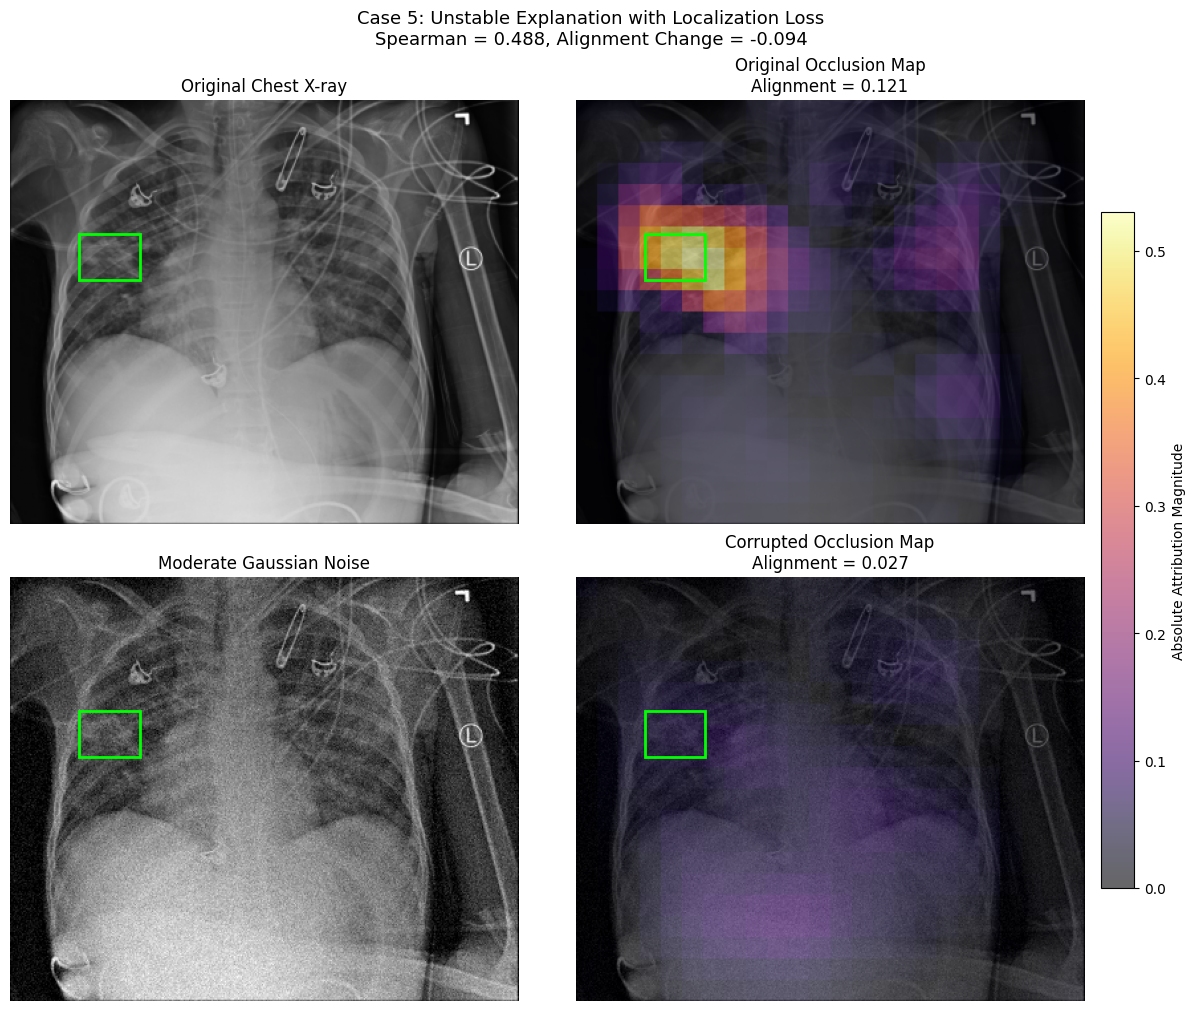

In [ ]:
# --------------------------------------------------
# Case 5: Occlusion Sensitivity visualization
# --------------------------------------------------

shared_vmin5 = 0.0
shared_vmax5 = max(float(np.max(original_map5)), float(np.max(corrupted_map5)))

assert shared_vmax5 > 0

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape5 = pair5["original"].shape

# Panel 1: Original chest X-ray
axes[0, 0].imshow(pair5["original"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[0, 0], boxes5, image_shape5)
axes[0, 0].set_title("Original Chest X-ray")

# Panel 2: Original Occlusion Sensitivity map
axes[0, 1].imshow(pair5["original"], cmap="gray", vmin=0, vmax=1)

heatmap5 = axes[0, 1].imshow(
    original_map5, cmap="inferno", alpha=0.6, vmin=shared_vmin5, vmax=shared_vmax5
)

draw_opacity_boxes(axes[0, 1], boxes5, image_shape5)
axes[0, 1].set_title(
    f"Original Occlusion Map\n" f"Alignment = {original_alignment5:.3f}"
)

# Panel 3: Moderate Gaussian noise
axes[1, 0].imshow(pair5["corrupted"], cmap="gray", vmin=0, vmax=1)
draw_opacity_boxes(axes[1, 0], boxes5, image_shape5)
axes[1, 0].set_title("Moderate Gaussian Noise")

# Panel 4: Corrupted Occlusion Sensitivity map
axes[1, 1].imshow(pair5["corrupted"], cmap="gray", vmin=0, vmax=1)

axes[1, 1].imshow(
    corrupted_map5, cmap="inferno", alpha=0.6, vmin=shared_vmin5, vmax=shared_vmax5
)

draw_opacity_boxes(axes[1, 1], boxes5, image_shape5)
axes[1, 1].set_title(
    f"Corrupted Occlusion Map\n" f"Alignment = {corrupted_alignment5:.3f}"
)

# Formatting
for ax in axes.flat:
    ax.axis("off")

colorbar = fig.colorbar(heatmap5, ax=axes[:, 1], shrink=0.75, pad=0.03)

colorbar.set_label("Absolute Attribution Magnitude")

fig.suptitle(
    "Case 5: Unstable Explanation with Localization Loss\n"
    f"Spearman = {similarity5:.3f}, "
    f"Alignment Change = {alignment_change5:.3f}",
    fontsize=13,
)

plt.show()


### Case 5 Interpretation: Explanation Instability with Localization Loss

Case 5 examines Occlusion Sensitivity for a correctly classified lung-opacity image subjected to moderate Gaussian noise (σ = 0.05).

**Original explanation:** The attribution map shows a prominent region of high attribution partially overlapping the radiologist-annotated opacity box. The original localization alignment is 0.1207, indicating that approximately 12.07% of total attribution magnitude falls within the annotated region.

**Corrupted explanation:** Following Gaussian noise, the original high-attribution region becomes substantially less pronounced, and the attribution appears weaker and more spatially dispersed. Localization alignment decreases to 0.0269.

**Explanation stability:** Spearman rank correlation between the original and corrupted attribution maps is 0.4876, indicating relatively low similarity in attribution rankings. Localization alignment decreases by approximately 9.39 percentage points.

**Interpretation:** Unlike the high-stability disagreement cases, this example demonstrates that substantial localization loss can also accompany explanation instability. The visualization suggests changes in both the spatial distribution and magnitude of attribution following image corruption.

**Limitations:** This is one selected image-corruption pair. The results do not establish whether Gaussian noise consistently produces similar changes across the full dataset. Attribution magnitude changes should also be interpreted cautiously because they can depend on the explanation method and its implementation.



### 11.9. Case 6: Integrated Gradients Under Moderate Gaussian Blur

Case 6 examines an Integrated Gradients explanation for a correctly classified lung-opacity image subjected to moderate Gaussian blur (σ = 1.5).

The saved audit indicates relatively low explanation similarity and a substantial decrease in localization alignment. This case provides an additional example of explanation instability accompanied by localization loss, using a different attribution method and corruption type from Case 5.

The original and corrupted attribution maps are regenerated using the original predicted class as the fixed explanation target. Their numerical measurements are compared with the saved audit before visualization.


In [ ]:
# --------------------------------------------------
# 1. Select Case 6
# --------------------------------------------------

case6 = selected_cases.iloc[5]
pair6 = image_pairs[5]

uid6 = str(case6["sop_uid"])
target_class6 = int(case6["original_predicted_class"])
boxes6 = opacity_lookup.get(uid6, [])

assert case6["method"] == "Integrated Gradients"
assert case6["corruption"] == "Blur"
assert case6["severity"] == "moderate"
assert len(boxes6) > 0

print("Method:", case6["method"])
print("Corruption:", case6["corruption"])
print("Severity:", case6["severity"])
print("Target class:", target_class6)


# --------------------------------------------------
# 2. Regenerate Integrated Gradients maps
# --------------------------------------------------

original_result6 = generate_ig_explanation(pair6["original"], target_class6)

corrupted_result6 = generate_ig_explanation(pair6["corrupted"], target_class6)

# Extract magnitude maps from the returned dictionaries
original_map6 = original_result6["magnitude_map"]
corrupted_map6 = corrupted_result6["magnitude_map"]

# Extract convergence diagnostics
original_delta6 = original_result6["convergence_delta"]
corrupted_delta6 = corrupted_result6["convergence_delta"]

# Validate map dimensions
assert original_map6.shape == pair6["original"].shape
assert corrupted_map6.shape == pair6["corrupted"].shape

print("Original map shape:", original_map6.shape)
print("Corrupted map shape:", corrupted_map6.shape)
print("Original IG convergence delta:", original_delta6)
print("Corrupted IG convergence delta:", corrupted_delta6)

# --------------------------------------------------
# 3. Recalculate numerical measurements
# --------------------------------------------------

similarity6 = spearmanr(original_map6.ravel(), corrupted_map6.ravel()).statistic

original_alignment6 = calculate_alignment(original_map6, boxes6)

corrupted_alignment6 = calculate_alignment(corrupted_map6, boxes6)

alignment_change6 = corrupted_alignment6 - original_alignment6

# --------------------------------------------------
# 4. Compare with the saved audit
# --------------------------------------------------

validation6 = pd.DataFrame(
    {
        "Metric": [
            "Explanation similarity",
            "Original alignment",
            "Corrupted alignment",
            "Alignment change",
        ],
        "Saved audit": [
            case6["explanation_similarity"],
            case6["original_alignment"],
            case6["localization_alignment"],
            case6["alignment_change"],
        ],
        "Recomputed": [
            similarity6,
            original_alignment6,
            corrupted_alignment6,
            alignment_change6,
        ],
    }
)

validation6["Absolute difference"] = (
    validation6["Saved audit"] - validation6["Recomputed"]
).abs()

display(validation6.round(6))

print("\nOriginal IG convergence delta:", original_delta6)
print("Corrupted IG convergence delta:", corrupted_delta6)

if (
    np.isfinite(validation6["Recomputed"]).all()
    and (validation6["Absolute difference"] < 1e-3).all()
):
    print("\nPASS: Case 6 metrics match the saved audit.")
else:
    print("\nCHECK: Case 6 metrics differ from the saved audit.")

Method: Integrated Gradients
Corruption: Blur
Severity: moderate
Target class: 1
Original map shape: (320, 384)
Corrupted map shape: (320, 384)
Original IG convergence delta: -0.025421500205993652
Corrupted IG convergence delta: -0.016994118690490723


,Metric,Saved audit,Recomputed,Absolute difference
0,Explanation similarity,0.563105,0.563105,0.0
1,Original alignment,0.347337,0.347337,0.0
2,Corrupted alignment,0.253409,0.253409,0.0
3,Alignment change,-0.093928,-0.093928,0.0



Original IG convergence delta: -0.025421500205993652
Corrupted IG convergence delta: -0.016994118690490723

PASS: Case 6 metrics match the saved audit.


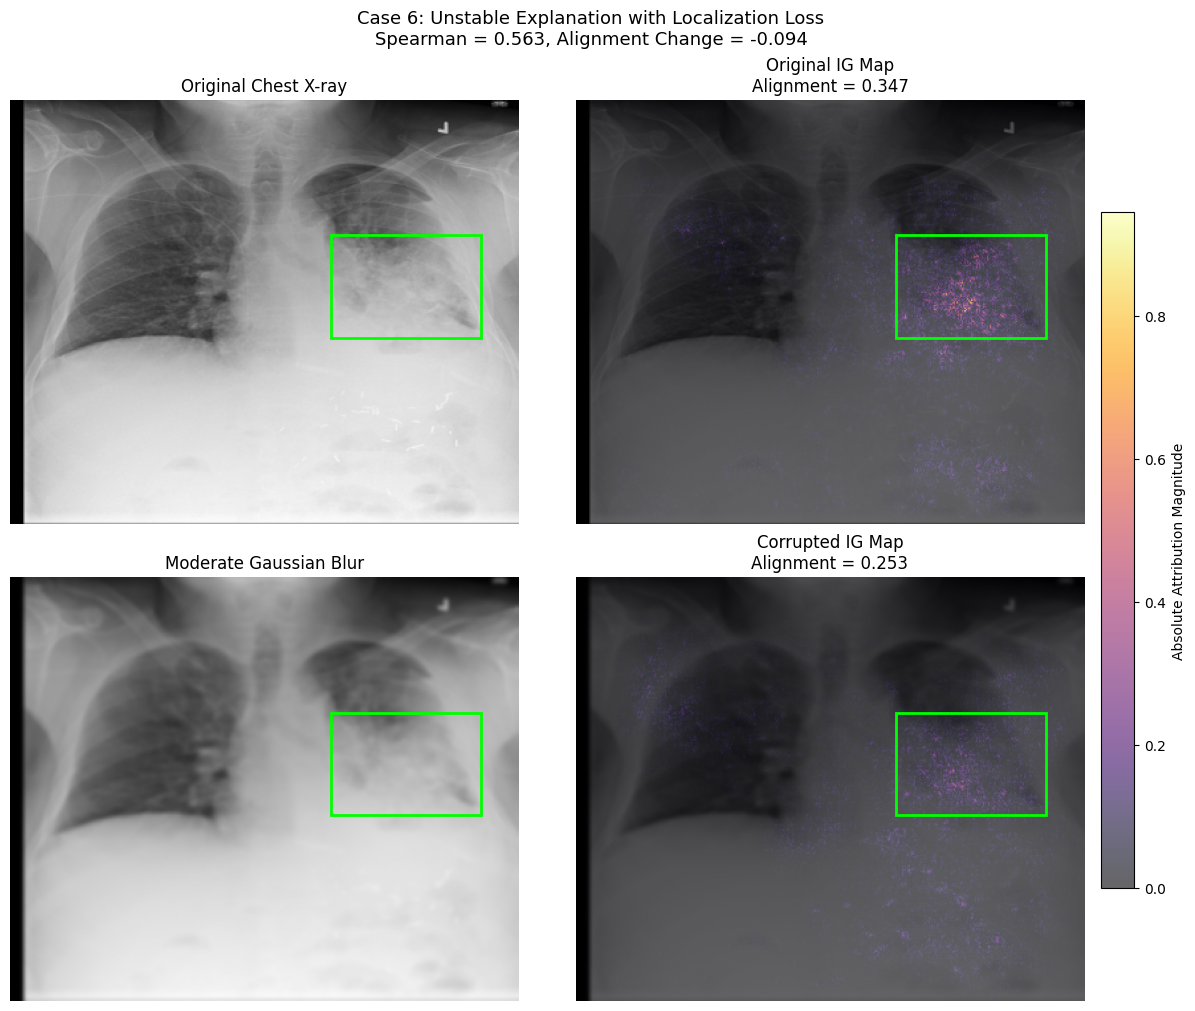

In [ ]:
# --------------------------------------------------
# Case 6: Integrated Gradients visualization
# --------------------------------------------------

shared_vmin6 = 0.0
shared_vmax6 = max(float(np.max(original_map6)), float(np.max(corrupted_map6)))

assert shared_vmax6 > 0

fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

image_shape6 = pair6["original"].shape

# Panel 1: Original chest X-ray
axes[0, 0].imshow(pair6["original"], cmap="gray", vmin=0, vmax=1)

draw_opacity_boxes(axes[0, 0], boxes6, image_shape6)

axes[0, 0].set_title("Original Chest X-ray")

# Panel 2: Original Integrated Gradients map
axes[0, 1].imshow(pair6["original"], cmap="gray", vmin=0, vmax=1)

heatmap6 = axes[0, 1].imshow(
    original_map6, cmap="inferno", alpha=0.6, vmin=shared_vmin6, vmax=shared_vmax6
)

draw_opacity_boxes(axes[0, 1], boxes6, image_shape6)

axes[0, 1].set_title(f"Original IG Map\n" f"Alignment = {original_alignment6:.3f}")

# Panel 3: Moderate Gaussian blur
axes[1, 0].imshow(pair6["corrupted"], cmap="gray", vmin=0, vmax=1)

draw_opacity_boxes(axes[1, 0], boxes6, image_shape6)

axes[1, 0].set_title("Moderate Gaussian Blur")

# Panel 4: Corrupted Integrated Gradients map
axes[1, 1].imshow(pair6["corrupted"], cmap="gray", vmin=0, vmax=1)

axes[1, 1].imshow(
    corrupted_map6, cmap="inferno", alpha=0.6, vmin=shared_vmin6, vmax=shared_vmax6
)

draw_opacity_boxes(axes[1, 1], boxes6, image_shape6)

axes[1, 1].set_title(f"Corrupted IG Map\n" f"Alignment = {corrupted_alignment6:.3f}")

# Remove axes
for ax in axes.flat:
    ax.axis("off")

# Shared colorbar
colorbar = fig.colorbar(heatmap6, ax=axes[:, 1], shrink=0.75, pad=0.03)

colorbar.set_label("Absolute Attribution Magnitude")

# Figure title
fig.suptitle(
    "Case 6: Unstable Explanation with Localization Loss\n"
    f"Spearman = {similarity6:.3f}, "
    f"Alignment Change = {alignment_change6:.3f}",
    fontsize=13,
)

plt.show()


### Case 6 Interpretation: Integrated Gradients Instability Under Moderate Blur

Case 6 examines Integrated Gradients for a correctly classified lung-opacity image subjected to moderate Gaussian blur (σ = 1.5).

**Original explanation:** The attribution map shows a prominent concentration of attribution within the radiologist-annotated opacity region, alongside weaker attribution in other image regions. Original localization alignment is 0.3473, indicating that approximately 34.73% of total attribution magnitude falls within the annotated region.

**Corrupted explanation:** Following moderate Gaussian blur, attribution remains visible within the annotated opacity region, but its intensity and spatial distribution change. Localization alignment decreases to 0.2534.

**Explanation stability:** Spearman rank correlation is 0.5631, indicating a moderate positive association between original and corrupted attribution rankings. This falls below the exploratory high-stability threshold of 0.80. Localization alignment decreases by approximately 9.39 percentage points.

**Interpretation:** This case demonstrates that localization loss can accompany substantial changes in attribution rankings. Unlike the high-stability disagreement cases, the decrease in localization alignment occurs alongside explanation instability. The visualization also illustrates that attribution can remain visibly present within an annotated region even when the proportion of attribution concentrated there decreases.

**Integrated Gradients diagnostics:** The original and corrupted convergence deltas are approximately −0.0254 and −0.0170, respectively. These values are retained as completeness diagnostics.

**Limitations:** The findings concern one selected image-corruption pair. Attribution overlap with radiologist annotations is a localization measure and does not independently establish explanation faithfulness or clinical reliability.



## 12. Synthesis and Conclusions

### 12.1. Summary of the Localization Analysis

This notebook extended the stability–localization audit by accounting for the area occupied by radiologist-annotated opacity bounding boxes and visually examining six selected image-corruption pairs.

All 150 annotated positive images in the audit were successfully matched to opacity bounding boxes. The annotated regions occupied an average of 11.03% of image area, with a median of 8.03%.

Area-adjusted attribution enrichment was calculated as:

$
\text{Attribution Enrichment} =
\frac{\text{Localization Alignment}}{\text{Bounding-Box Area Fraction}}
$

An enrichment value greater than 1 indicates that attribution is more concentrated within the annotated regions than would be expected under a spatially uniform attribution distribution.

Across 2,700 image-method-corruption evaluations, mean attribution enrichment decreased from 3.5148 in the original explanations to 2.6500 in the corrupted explanations. Mean enrichment change was −0.8649.

The mean enrichment changes differed descriptively across methods:

- Integrated Gradients: −1.0318
- Occlusion Sensitivity: −0.8468
- Score-CAM: −0.7160

These comparisons are descriptive because evaluations from the same images are repeated across methods and corruption conditions.

### 12.2. Influence of Bounding-Box Size

Smaller annotated regions were associated with larger absolute enrichment changes.

Spearman correlations between bounding-box area fraction and absolute enrichment change were:

- Integrated Gradients: −0.3602
- Occlusion Sensitivity: −0.3716
- Score-CAM: −0.2844

Because enrichment divides localization alignment by bounding-box area fraction, small annotated regions can amplify the numerical magnitude of enrichment changes. Consequently, enrichment should be interpreted alongside raw localization alignment and bounding-box coverage rather than as a standalone measure.

For a given image, bounding-box area remains fixed across corruption conditions. Area adjustment therefore preserves the direction of localization change, although it changes the magnitude of the reported difference.

### 12.3. Comparison of Selected Cases

Six image-corruption pairs were selected to illustrate three patterns:

| Pattern | Cases | Observation |
|---|---|---|
| High stability with localization loss | 1 and 2 | Attribution rankings remained relatively similar while localization alignment decreased substantially. |
| High stability without substantial localization loss | 3 and 4 | Attribution rankings remained relatively similar, with minimal change in localization alignment. |
| Lower stability with localization loss | 5 and 6 | Attribution rankings changed more substantially while localization alignment also decreased. |

All six selected cases were regenerated using the trained ResNet-50 model and the original predicted class as the fixed explanation target.

The recomputed explanation similarities and localization measurements matched their saved audit values.

The visualizations show that changes in attribution rankings, spatial concentration, and attribution magnitude can occur in different combinations.

### 12.4. Interpretation

The quantitative and qualitative findings demonstrate why explanation stability and localization alignment should be evaluated separately.

Cases 1 and 2 illustrate the central disagreement pattern: explanation maps retained relatively high pixelwise rank similarity under corruption, yet a smaller proportion of attribution magnitude remained within the radiologist-annotated opacity regions.

Cases 3 and 4 provide contrasting examples in which high explanation stability was accompanied by minimal localization change. Importantly, preserved localization alignment does not necessarily indicate strong localization in the original explanation, as demonstrated by Case 3.

Cases 5 and 6 illustrate that lower explanation similarity can also accompany substantial localization loss.

Area-adjusted enrichment provides additional context by relating attribution concentration to annotated region size. However, because enrichment change divides alignment change by a fixed area fraction for each image, it does not independently establish localization degradation.

Together, these findings indicate that rank-based explanation stability alone does not fully characterize attribution behavior under image corruption. Nevertheless, annotation-based localization overlap should not be interpreted as proof of explanation faithfulness or clinical correctness.

The six visualized cases were deliberately selected to illustrate contrasting patterns and should not be treated as representative prevalence estimates.

### 12.5. Limitations

1. Localization alignment measures attribution overlap with radiologist-annotated opacity regions, not explanation faithfulness or clinical correctness.
2. Bounding boxes approximate opacity locations and may not capture their precise boundaries.
3. Area-adjusted enrichment can be sensitive to small bounding-box fractions.
4. The analysis includes repeated evaluations of the same images across methods and corruption conditions.
5. The visualized cases were purposefully selected rather than randomly sampled.
6. Attribution maps from different explanation methods have different construction and scaling conventions, limiting direct comparisons of their raw magnitudes.
7. The localization analysis is restricted to annotated lung-opacity-positive images and does not characterize explanation behavior on negative images.
8. The complete positive-image audit includes both originally correct positive predictions and originally false-negative predictions. Explanations were generated for the original predicted class, which was held fixed under corruption. For false-negative images, this means the explanation targets the negative class even though localization is measured against radiologist-annotated positive-opacity regions. Consequently, localization measurements for false-negative predictions require a different interpretation from those for true-positive predictions.


### 12.6. Conclusion

The localization analysis demonstrates that explanation stability alone is insufficient to characterize how attribution behaves under image corruption.

The combination of rank-based explanation similarity, annotation-based localization alignment, area-adjusted enrichment, and qualitative visualization provides a more complete description of attribution behavior.

The results motivate examining explanation behavior on negative images, where radiologist-annotated opacity boxes are generally unavailable and alternative spatial evaluation strategies are required.



## 13. Exporting the Enriched Audit Results

The enriched localization audit is exported as a CSV file for subsequent analysis.

Before exporting, the dataset is validated to confirm that all 2,700 evaluations, 150 unique images, and required enrichment measurements are present. The calculated enrichment summaries are also checked against the results reported in this notebook.

The exported file preserves the original evaluation measurements alongside the bounding-box area fractions and area-adjusted attribution enrichment metrics.


In [ ]:
# --------------------------------------------------
# Save Notebook 08 enriched audit results
# --------------------------------------------------

from pathlib import Path
import pandas as pd
import numpy as np

OUTPUT_PATH = RESULTS_DIR / "stability_localization_area_enriched.csv"

required_columns = [
    "sop_uid",
    "method",
    "corruption",
    "severity",
    "box_area_fraction",
    "localization_alignment",
    "original_alignment",
    "alignment_change",
    "attribution_enrichment",
    "original_enrichment",
    "enrichment_change",
]

# Validate the correct DataFrame
assert all(col in area_audit.columns for col in required_columns)
assert len(area_audit) == 2700
assert area_audit["sop_uid"].nunique() == 150
assert area_audit["box_area_fraction"].notna().all()
assert (area_audit["box_area_fraction"] > 0).all()

# Check expected enrichment results
summary = area_audit[
    ["attribution_enrichment", "original_enrichment", "enrichment_change"]
].mean()

print("Enrichment summary:")
print(summary.round(4))

assert np.isclose(summary["attribution_enrichment"], 2.649963, atol=1e-4)

assert np.isclose(summary["original_enrichment"], 3.514823, atol=1e-4)

assert np.isclose(summary["enrichment_change"], -0.864860, atol=1e-4)

# Save without overwriting the original audit
area_audit.to_csv(OUTPUT_PATH, index=False)

# Reload and verify
saved_audit = pd.read_csv(OUTPUT_PATH)

assert saved_audit.shape == area_audit.shape
assert list(saved_audit.columns) == list(area_audit.columns)

print("\nSaved successfully:", OUTPUT_PATH)
print("Rows:", len(saved_audit))
print("Unique images:", saved_audit["sop_uid"].nunique())
print("Columns:", len(saved_audit.columns))

Enrichment summary:
attribution_enrichment    2.6500
original_enrichment       3.5148
enrichment_change        -0.8649
dtype: float64

Saved successfully: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/ExpandedEvaluation/stability_localization_area_enriched.csv
Rows: 2700
Unique images: 150
Columns: 24
